# 2026 年中国研究生数学建模竞赛 F 题 · 问题三
## 算力约束下的风险可执行资源联合优化与结构性转移

> **赛题任务**：在总算力预算 \(C\) 有限时，在参数量 \(N\)、数据量 \(D\)、数据质量 \(Q_A\) 与领域配比 \(\mathbf p\) 之间分配资源，并分析预算跨越量级时最优策略是否发生本质改变。上下文长度 \(L_{ctx}\) 为外生架构变量，其可行值来自 C7。
>
> **建模边界**：本问只消费问题一、二已经建立的证据，不重新利用问题三结果反向拟合领域配比、质量效应或 Scaling Law 参数。特别地，问题二的 \(p_{\rm ref}\) 保持“理论归一化参考点”身份，不进入可执行策略集合。

### 技术路线

```text
问题一
├─ Q_i：领域质量
├─ p_risk：风险控制推荐
├─ p_safe：支撑域内推荐（若接口可获得）
└─ p_measured：实测最佳配方（若接口可获得）
             │
             ▼
      可执行集合 P_exec
             │
问题二        │
├─ SAED: E,A,α,B,β, κ
├─ 质量桥 T(Q_A;c_Q)
├─ 配比尺度迁移 γ_p
└─ p_ref：仅作 ψ_p0=1 的理论参考
             │
             ▼
  相对质量因子 ψ~_Q(Q_A;p)
  = ψ_Q[T(Q_A)] / ψ_Q[T(Q0,A(p))]
  （Q=Q0 时恒为 1，避免 p→Q0→ψ_Q 的双重计数）
             │
             ▼
 min L = E + [A N^-α + B D^-β] · ψ~_Q · ψ_p(p,N)
 s.t. D[(6+ηL_ctx)N + g(Q_A)-g(Q0,A(p))] ≤ C
             │
    ┌────────┴────────┐
    │                 │
 P_exec 外层      KKT 主动集
    │                 │
    └──────► 可执行最优策略
             │
   p_ref 单独求理论参考下界
             │
             ▼
  continuation + value crossing
  → R0/R1/R2 结构转移
             │
             ▼
  Q2 参数不确定性联合情景
  → minimax-regret / stress test
             │
             ▼
       输出问题四接口
```

### 三个角色必须严格区分

| 配比 | 角色 | 是否可执行 |
|---|---|---|
| \(p_{\rm risk}\) | 问题一风险控制推荐 | 是 |
| \(p_{\rm safe}\) | 支撑域内代理推荐（若已导出） | 是 |
| \(p_{\rm measured}\) | 已观测最优配方（若已导出） | 是 |
| \(p_{\rm ref}\) | 问题二结构桥归一化 / 理论参考 | **否** |

### 数据与路径

* 问题二接口：`./output_q2/tables/q2_outputs_for_q3.json`
* 问题一接口：优先读取 `./解题思路/问题一_最终整合结果/tables/`，其次 `./output_q1/tables/`
* C7：`./real_attachments/C_efficiency_evolution/model_architecture_metadata.csv`
* 图表：`./output_q3/figures/`
* 表格与问题四接口：`./output_q3/tables/`


In [32]:
# ============ 0. 环境配置 ============
import os, json, math, time, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

from scipy.optimize import brentq

warnings.filterwarnings('ignore')
pd.set_option('display.width', 190)
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda v: '%.6g' % v)

# ============ 中英文论文绘图字体配置 ============
import os
import re
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from pathlib import Path

# --------------------------------------------------
# 1. 字体文件路径
# --------------------------------------------------
# Windows 本机运行时通常是下面路径。
# 如果是在 Linux/远程服务器运行，请改成服务器中字体的真实路径。

WIN_SIMSUN = Path(r'C:\Windows\Fonts\simsun.ttc')
WIN_TIMES  = Path(r'C:\Windows\Fonts\times.ttf')

SIMSUN_PATH = WIN_SIMSUN if WIN_SIMSUN.exists() else None
TIMES_PATH  = WIN_TIMES  if WIN_TIMES.exists() else None


# --------------------------------------------------
# 2. 如果系统字体管理器已经能找到，就直接使用
# --------------------------------------------------
def find_font_path(font_name):
    try:
        return Path(fm.findfont(font_name, fallback_to_default=False))
    except Exception:
        return None

if SIMSUN_PATH is None:
    SIMSUN_PATH = find_font_path('SimSun')

if TIMES_PATH is None:
    TIMES_PATH = find_font_path('Times New Roman')


# --------------------------------------------------
# 3. 强制检查，不再静默回退到 DejaVu Sans
# --------------------------------------------------
if SIMSUN_PATH is None or not SIMSUN_PATH.exists():
    raise RuntimeError(
        '没有找到宋体 SimSun。\n'
        '请确认运行 Notebook 的 Python 环境中存在 simsun.ttc，'
        '并把 SIMSUN_PATH 改成它的真实路径。'
    )

if TIMES_PATH is None or not TIMES_PATH.exists():
    raise RuntimeError(
        '没有找到 Times New Roman。\n'
        '请确认运行 Notebook 的 Python 环境中存在 times.ttf，'
        '并把 TIMES_PATH 改成它的真实路径。'
    )


# --------------------------------------------------
# 4. 显式注册字体
# --------------------------------------------------
fm.fontManager.addfont(str(SIMSUN_PATH))
fm.fontManager.addfont(str(TIMES_PATH))

ZH_FONT = fm.FontProperties(fname=str(SIMSUN_PATH)).get_name()
EN_FONT = fm.FontProperties(fname=str(TIMES_PATH)).get_name()

print('中文字体:', ZH_FONT, '->', SIMSUN_PATH)
print('英文字体:', EN_FONT, '->', TIMES_PATH)


# --------------------------------------------------
# 5. 全局字体
# --------------------------------------------------
# 英文/数字首先使用 Times New Roman；
# 中文字形缺失时 fallback 到 SimSun
mpl.rcParams['font.family'] = [EN_FONT, ZH_FONT]
mpl.rcParams['font.serif'] = [EN_FONT, ZH_FONT]

# 数学公式采用 Times 系
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = EN_FONT
mpl.rcParams['mathtext.it'] = EN_FONT + ':italic'
mpl.rcParams['mathtext.bf'] = EN_FONT + ':bold'

mpl.rcParams['axes.unicode_minus'] = False

# PDF / PS 字体
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

# PDF / PS 中保留可编辑 TrueType 字体
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#E4E4E4'
plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['axes.edgecolor'] = '#555555'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['font.size'] = 10

C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, C_GREY, C_MOSS = (
    '#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#9E9E9E', '#8AB17D'
)
CMAP_L = mpl.colors.LinearSegmentedColormap.from_list(
    'lctx', ['#0B2545', '#2A9D8F', '#E9C46A', '#E76F51', '#7A1F1F']
)
CMAP_SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    'seq', ['#F7F9FB', '#9FC5D6', '#4E8FA8', '#1F3A5F']
)
COL_COST = {'指数型': C_NAVY, '幂函数型': C_CORAL, '对数渐进型': C_PLUM}
LS_COST = {'指数型': '-', '幂函数型': '--', '对数渐进型': '-.'}
COL_REG = {'R0': '#D9D9D9', 'R1': '#F3E1A6', 'R2': '#BFE3DC'}
NAME_REG = {
    'R0': 'R0：不追加质量投资',
    'R1': 'R1：部分质量投资',
    'R2': 'R2：质量拉满'
}
plain = mpl.ticker.FuncFormatter(lambda v, _: '%g' % v)
pow10 = mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(np.log10(v))) if v > 0 else '')

# ---------- 自动寻找 F 题根目录 ----------
CWD = Path('.').resolve()
SEARCH = []
for p in [CWD, *CWD.parents]:
    SEARCH.extend([p, p / 'F题'])
seen = set()
SEARCH = [p for p in SEARCH if not (str(p) in seen or seen.add(str(p)))]

F_ROOT = next(
    (p for p in SEARCH
     if (p / 'real_attachments' / 'C_efficiency_evolution' / 'model_architecture_metadata.csv').exists()
     and (p / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json').exists()),
    None
)
if F_ROOT is None:
    raise FileNotFoundError(
        '未自动找到 F 题根目录。请先完整运行问题二，并保证 C7 与 '
        'output_q2/tables/q2_outputs_for_q3.json 存在。'
    )

BASE_DIR = F_ROOT
C7_PATH = F_ROOT / 'real_attachments' / 'C_efficiency_evolution' / 'model_architecture_metadata.csv'
Q2_JSON = F_ROOT / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json'
Q2 = json.loads(Q2_JSON.read_text(encoding='utf-8'))

# 问题一：加载可获得的全部 JSON，专门用于角色化候选检索
Q1_TABLE_CANDIDATES = [
    F_ROOT / '解题思路' / '问题一_最终整合结果' / 'tables',
    F_ROOT / 'output_q1' / 'tables',
]
Q1_TABLE = next((p for p in Q1_TABLE_CANDIDATES if p.exists()), None)
Q1_OBJECTS = []
if Q1_TABLE is not None:
    for jp in Q1_TABLE.glob('*.json'):
        try:
            Q1_OBJECTS.append((jp.name, json.loads(jp.read_text(encoding='utf-8'))))
        except Exception:
            pass

required_q2 = {'classic_law','quality','mixture_scale_transfer','mixture_bridge','cost_functions_appendixB'}
missing = required_q2 - set(Q2)
if missing:
    raise KeyError(f'问题二接口缺少字段: {sorted(missing)}；实际键={list(Q2.keys())}')

OUT = F_ROOT / 'output_q3'
FIG = OUT / 'figures'
TAB = OUT / 'tables'
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG / name, dpi=300, bbox_inches='tight', facecolor='white')

print('F题根目录:', F_ROOT)
print('问题二模型:', Q2.get('model_name'))
print('问题一 JSON 数量:', len(Q1_OBJECTS))
print('输出目录:', OUT)


中文字体: SimSun -> C:\Windows\Fonts\simsun.ttc
英文字体: Times New Roman -> C:\Windows\Fonts\times.ttf
F题根目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题
问题二模型: SAED-Modular-Separable
问题一 JSON 数量: 3
输出目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\output_q3


## 1. 输入台账：前两问参数、配比角色与 C7 上下文长度

### 1.1 SAED 参数

问题二提供

\[
L=E+(AN^{-\alpha}+BD^{-\beta})\psi_Q(Q_B)\psi_p(\mathbf p,N),
\]

其中

\[
Q_B=T(Q_A;c_Q),\qquad
\psi_Q(Q_B)=1+\kappa(1-Q_B),
\]

\[
\psi_p(\mathbf p,N)
=
1+\left(\frac{N}{N_0}\right)^{-\gamma_p}
[\psi_{p,0}(\mathbf p)-1].
\]

本问完整继承上述参数，不重新拟合。

### 1.2 配比角色标准化

这里不把所有数学上可计算的配比都当成可执行策略。代码优先从问题一接口中寻找：

* `risk_recipe_p / p_risk`：风险控制推荐；
* `supported_recipe_p / p_safe`：支撑域内推荐；
* `measured_best_recipe_p / p_measured`：实测最佳配方。

若某一角色未被问题一正式导出，就**不猜测、不补造**。问题二的 \(p_{\rm ref}\) 独立保存为 theoretical reference，仅用于结构归一化和乐观参考下界。

### 1.3 质量基线只表示“治理起点”

对任一可执行配比 \(\mathbf p\)，定义

\[
Q_{0,A}(\mathbf p)=\sum_i p_iQ_i
\]

仅用于：

1. 质量治理的起始状态；
2. 质量投资成本 \(g(Q_A)-g(Q_{0,A})\)。

它不再作为一条独立的 baseline 性能通道直接进入 Loss。这样与问题一“领域均值质量不应再次重写配比 Loss”的结论保持一致。

### 1.4 C7 与长上下文临界值

\[
\frac{C_{attn}}{C_{train}}=\frac{\eta L_{ctx}}6,
\qquad
L_{ctx}^{crit}=\frac6\eta=30000.
\]

C7 给出的真实 \(L_{ctx}\) 可行集同时覆盖临界值两侧，因此可直接研究长上下文对最优资源配置与转移边界的影响。


参数台账：


,参数,取值,含义
0,E,1.68984,不可约损失
1,A,406.298,参数项系数
2,alpha,0.339987,参数指数
3,B,409.784,数据项系数
4,beta,0.279893,数据指数
5,kappa,0.459661,"质量效应；CI [0.4378,0.4873]"
6,gamma_p,0.0686435,"matched 1M→60M；bootstrap [0.0574,0.0790]"
7,c_Q,1,"质量坐标桥；敏感性 [0.75, 1.25]"
8,eta,0.0002,注意力开销系数
9,L_crit,30000,注意力 = 基础训练



配比角色台账：


,p_name,role,executable,Q0_A,psi_p0,source
0,p_risk,risk-controlled recommendation,True,0.622345,1.03702,Q2.mixture_bridge.p_risk
1,p_ref,normalization reference / theoretical oracle,False,0.618067,1,Q2.mixture_bridge.p_ref



C7: 45 个模型；L_ctx 可行集=[2048, 4096, 8192, 32768, 131072]；默认=4096；L_crit=30000


Font 'default' does not have a glyph for '\u7ed3' [U+7ed3], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u6784' [U+6784], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u56e0' [U+56e0], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u5b50' [U+5b50], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u57fa' [U+57fa], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u7ebf' [U+7ebf], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u8d28' [U+8d28], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u91cf' [U+91cf], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u7ed3' [U+7ed3], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u6784' [U+6784], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u56e0' [U+56e0], 

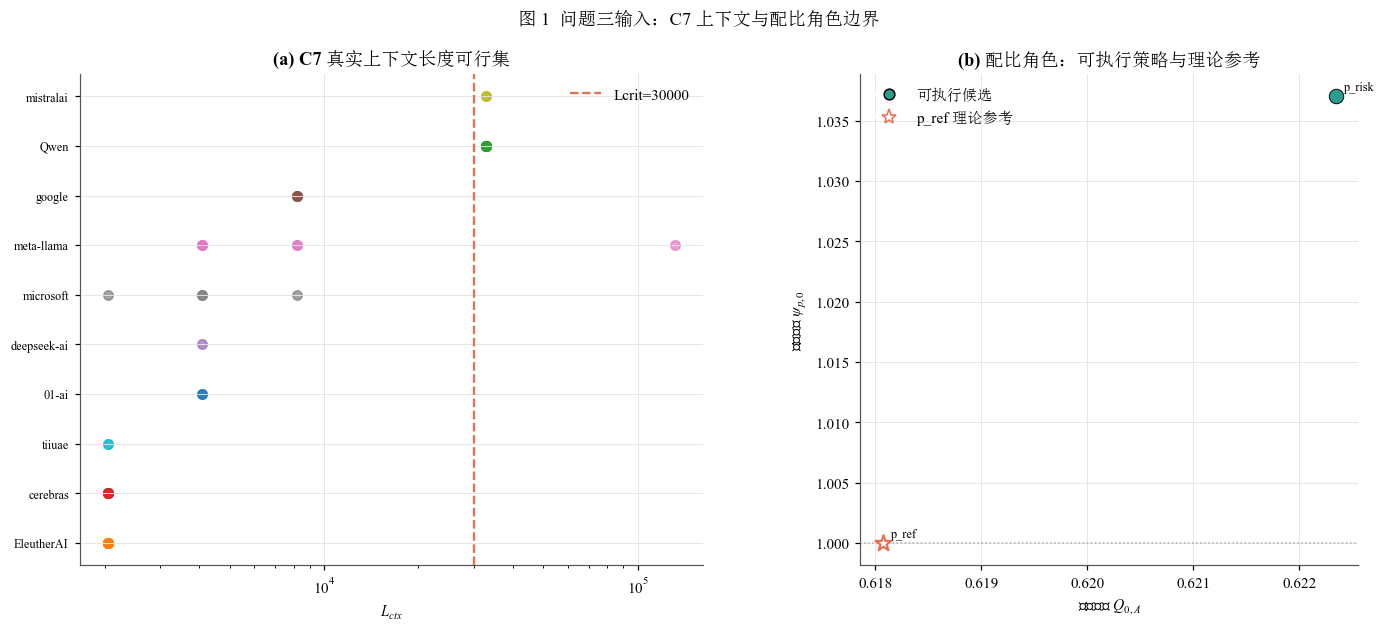

In [33]:
# ============ 1. 参数、配比角色与 C7 ============
TH = {k: float(Q2['classic_law'][k]) for k in ('E','A','alpha','B','beta')}

QUAL = Q2['quality']
KAPPA = float(QUAL['kappa'])
EXP_UNC = Q2.get('H1', {}).get('exponent_uncertainty', {})
KAPPA_CI = list(map(float, EXP_UNC.get('kappa_ci_B6_cluster', [KAPPA, KAPPA])))
if len(KAPPA_CI) != 2:
    KAPPA_CI = [KAPPA, KAPPA]

QBR = QUAL['Q_bridge']
CQ_NOMINAL = float(QBR.get('nominal_c_Q', 1.0))
CQ_SCENARIOS = list(map(float, QBR.get('sensitivity_c_Q', [0.75, 1.25])))
Q_REF_A = float(QBR['Qbar_A_ref'])
Q_RISK_A = float(QBR['Qbar_A_risk'])

MST = Q2['mixture_scale_transfer']
N0_MIX = float(MST['N0'])
GAMMA_P = float(MST['gamma_p_local'])
GAMMA_CI = list(map(float, MST.get(
    'gamma_p_matched_bootstrap_2p5_50_97p5', [GAMMA_P, GAMMA_P, GAMMA_P]
)))
if len(GAMMA_CI) < 3:
    GAMMA_CI = [GAMMA_P, GAMMA_P, GAMMA_P]

MB = Q2['mixture_bridge']
DOM17 = list(MB['domain_order'])
C0_MIX = float(MB['intercept'])
EPS_LOG = float(MB['epsilon'])
L_REF = float(MB['L_ref'])
A_LOG = np.array([float(MB['a_i'][d]) for d in DOM17])
P_REF = np.array([float(MB['p_ref'][d]) for d in DOM17])
P_RISK = np.array([float(MB['p_risk'][d]) for d in DOM17])

G_PAR = Q2['cost_functions_appendixB']
ETA = 2e-4
L_CRIT = 6 / ETA
BUDGETS = [1e19, 1e22, 1e24]
BUD_LAB = {1e19:'低 1e19', 1e22:'中 1e22', 1e24:'高 1e24'}

def bridge_QA_to_QB(QA, c_q=None):
    c_q = CQ_NOMINAL if c_q is None else float(c_q)
    return np.clip(1.0 - c_q * (1.0 - np.asarray(QA, float)), 0.0, 1.0)

def psi_p0_vec(p):
    p = np.asarray(p, float)
    return float((C0_MIX + np.sum(A_LOG * np.log(p + EPS_LOG))) / L_REF)

def psi_p_at_N(N, psi_p0, gamma=None):
    gamma = GAMMA_P if gamma is None else float(gamma)
    return 1.0 + (np.asarray(N, float)/N0_MIX)**(-gamma) * (float(psi_p0)-1.0)

G_COST = {
    '指数型': (
        lambda Q: G_PAR['exp']['gamma'] * np.exp(G_PAR['exp']['lambda'] * np.asarray(Q,float)),
        lambda Q: G_PAR['exp']['gamma'] * G_PAR['exp']['lambda'] * np.exp(G_PAR['exp']['lambda'] * np.asarray(Q,float)),
        lambda Q: G_PAR['exp']['gamma'] * G_PAR['exp']['lambda']**2 * np.exp(G_PAR['exp']['lambda'] * np.asarray(Q,float))),
    '幂函数型': (
        lambda Q: G_PAR['power']['gamma'] * np.asarray(Q,float)**G_PAR['power']['lambda'],
        lambda Q: G_PAR['power']['gamma'] * G_PAR['power']['lambda'] * np.asarray(Q,float)**(G_PAR['power']['lambda']-1),
        lambda Q: G_PAR['power']['gamma'] * G_PAR['power']['lambda'] * (G_PAR['power']['lambda']-1) * np.asarray(Q,float)**(G_PAR['power']['lambda']-2)),
    '对数渐进型': (
        lambda Q: G_PAR['log']['gamma'] * np.log(1 + G_PAR['log']['lambda'] * np.asarray(Q,float)),
        lambda Q: G_PAR['log']['gamma'] * G_PAR['log']['lambda'] / (1 + G_PAR['log']['lambda'] * np.asarray(Q,float)),
        lambda Q: -G_PAR['log']['gamma'] * G_PAR['log']['lambda']**2 / (1 + G_PAR['log']['lambda'] * np.asarray(Q,float))**2)
}
COSTS = list(G_COST)

# ---------- 递归寻找问题一正式导出的配比角色 ----------
def _vector_from_obj(v):
    if isinstance(v, dict) and all(d in v for d in DOM17):
        p = np.array([float(v[d]) for d in DOM17], float)
        if np.all(np.isfinite(p)) and p.sum() > 0 and np.all(p >= -1e-12):
            p = np.maximum(p, 0)
            return p / p.sum()
    return None

def recursive_find_key(obj, target_keys):
    hits = []
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k in target_keys:
                p = _vector_from_obj(v)
                if p is not None:
                    hits.append((k, p))
            hits.extend(recursive_find_key(v, target_keys))
    elif isinstance(obj, list):
        for v in obj:
            hits.extend(recursive_find_key(v, target_keys))
    return hits

# 域质量向量：若 Q1 正式导出，则用于计算 p_safe / p_measured 的 Q0_A
Q17 = None
for _, obj in Q1_OBJECTS:
    hits = recursive_find_key(obj, {'mixture_domain_Q', 'domain_Q', 'Q_i'})
    if hits:
        # recursive_find_key 只抽配比型 dict，不适合 Q_i；下面单独找
        pass

def recursive_find_domain_q(obj):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k in {'mixture_domain_Q','domain_Q','Q_i'} and isinstance(v, dict) and all(d in v for d in DOM17):
                try:
                    return np.array([float(v[d]) for d in DOM17], float)
                except Exception:
                    pass
            out = recursive_find_domain_q(v)
            if out is not None:
                return out
    elif isinstance(obj, list):
        for v in obj:
            out = recursive_find_domain_q(v)
            if out is not None:
                return out
    return None

for _, obj in Q1_OBJECTS:
    Q17 = recursive_find_domain_q(obj)
    if Q17 is not None:
        break

ROLE_KEYS = {
    'p_safe': {'supported_recipe_p','p_safe','safe_recipe_p'},
    'p_measured': {'measured_best_recipe_p','p_measured','best_observed_p','best_train_recipe_p'},
    'p_risk': {'risk_recipe_p','p_risk'}
}

role_candidates = []
# p_risk 以 Q2 明确传入版本为主，避免命名混淆
role_candidates.append(('p_risk', P_RISK, 'risk-controlled recommendation', 'Q2.mixture_bridge.p_risk'))

for role, keys in ROLE_KEYS.items():
    if role == 'p_risk':
        continue
    found = None
    source = None
    for fname, obj in Q1_OBJECTS:
        hits = recursive_find_key(obj, keys)
        if hits:
            found = hits[0][1]
            source = f'{fname}:{hits[0][0]}'
            break
    if found is not None:
        role_candidates.append((role, found, 
                                'support-constrained recommendation' if role=='p_safe' else 'best measured recipe',
                                source))

def q0_for(role, p):
    if role == 'p_risk':
        return Q_RISK_A
    if Q17 is not None:
        return float(np.dot(p, Q17))
    return np.nan

rows = []
for role, p, evidence_role, source in role_candidates:
    q0 = q0_for(role, p)
    if not np.isfinite(q0):
        print(f'提示：{role} 已找到，但问题一未提供可核验的领域质量向量，故不进入可执行集合。')
        continue
    rows.append({
        'p_name': role, 'role': evidence_role, 'executable': True,
        'Q0_A': q0, 'psi_p0': psi_p0_vec(p), 'source': source
    })

EXEC = pd.DataFrame(rows).drop_duplicates('p_name').reset_index(drop=True)
if len(EXEC) == 0:
    raise RuntimeError('未构造出任何可执行配比。至少应存在 Q2 导出的 p_risk。')

EXEC_INFO = {
    r.p_name: {'Q0_A':float(r.Q0_A), 'psi_p0':float(r.psi_p0)}
    for _, r in EXEC.iterrows()
}

REF_INFO = {
    'p_name':'p_ref',
    'role':'normalization reference / theoretical oracle',
    'executable':False,
    'Q0_A':Q_REF_A,
    'psi_p0':psi_p0_vec(P_REF),
    'source':'Q2.mixture_bridge.p_ref'
}

ROLE_TABLE = pd.concat([
    EXEC[['p_name','role','executable','Q0_A','psi_p0','source']],
    pd.DataFrame([REF_INFO])
], ignore_index=True)

# ---------- C7 ----------
C7 = pd.read_csv(C7_PATH)
C7['family'] = C7.model_name.astype(str).str.split('/').str[0]
C7['L_ctx'] = C7.max_position_embeddings.astype(int)
FEAS = sorted(C7.L_ctx.unique().tolist())
L_DEFAULT = int(np.median(C7.L_ctx))
L_ALL = sorted(set(FEAS + [int(L_CRIT)]))

par_tab = pd.DataFrame([
    ('E',TH['E'],'不可约损失'), ('A',TH['A'],'参数项系数'), ('alpha',TH['alpha'],'参数指数'),
    ('B',TH['B'],'数据项系数'), ('beta',TH['beta'],'数据指数'),
    ('kappa',KAPPA,f'质量效应；CI [{KAPPA_CI[0]:.4f},{KAPPA_CI[1]:.4f}]'),
    ('gamma_p',GAMMA_P,f'matched 1M→60M；bootstrap [{GAMMA_CI[0]:.4f},{GAMMA_CI[-1]:.4f}]'),
    ('c_Q',CQ_NOMINAL,f'质量坐标桥；敏感性 {CQ_SCENARIOS}'),
    ('eta',ETA,'注意力开销系数'), ('L_crit',L_CRIT,'注意力 = 基础训练')
], columns=['参数','取值','含义'])

print('参数台账：')
display(par_tab)
print('\n配比角色台账：')
display(ROLE_TABLE)
print(f'\nC7: {len(C7)} 个模型；L_ctx 可行集={FEAS}；默认={L_DEFAULT}；L_crit={L_CRIT:.0f}')

ROLE_TABLE.to_csv(TAB/'mixture_role_ledger.csv', index=False, encoding='utf-8-sig')

# ---------- 图 1：沿用原有视觉语言，突出“可执行 vs 参考” ----------
fig = plt.figure(figsize=(15,5.8))
gs = gridspec.GridSpec(1,2,width_ratios=[1.25,1],wspace=0.28)

ax = fig.add_subplot(gs[0])
fams = C7.groupby('family').L_ctx.median().sort_values().index.tolist()
ypos = {f:i for i,f in enumerate(fams)}
for f,g in C7.groupby('family'):
    ax.scatter(g.L_ctx,[ypos[f]]*len(g),s=38,alpha=.72,label=None)
ax.axvline(L_CRIT,color=C_CORAL,ls='--',lw=1.5,label=f'Lcrit={L_CRIT:.0f}')
ax.set_xscale('log')
ax.set_yticks(range(len(fams))); ax.set_yticklabels(fams,fontsize=8)
ax.set_xlabel(r'$L_{ctx}$'); ax.set_title('(a) C7 真实上下文长度可行集')
ax.legend(frameon=False)

ax = fig.add_subplot(gs[1])
for _,r in ROLE_TABLE.iterrows():
    if r.executable:
        ax.scatter(r.Q0_A,r.psi_p0,s=90,marker='o',color=C_TEAL,edgecolor='black',linewidth=.6,zorder=3)
    else:
        ax.scatter(r.Q0_A,r.psi_p0,s=120,marker='*',facecolor='white',edgecolor=C_CORAL,linewidth=1.4,zorder=4)
    ax.annotate(r.p_name,(r.Q0_A,r.psi_p0),xytext=(5,4),textcoords='offset points',fontsize=8)
ax.axhline(1.0,color='#AAAAAA',ls=':',lw=1)
ax.set_xlabel(r'基线质量 $Q_{0,A}$')
ax.set_ylabel(r'结构因子 $\psi_{p,0}$')
ax.set_title('(b) 配比角色：可执行策略与理论参考')
ax.legend(handles=[
    Line2D([0],[0],marker='o',color='w',markerfacecolor=C_TEAL,markeredgecolor='black',label='可执行候选',markersize=7),
    Line2D([0],[0],marker='*',color='w',markerfacecolor='white',markeredgecolor=C_CORAL,label='p_ref 理论参考',markersize=10)
],frameon=False,loc='best')
fig.suptitle('图 1  问题三输入：C7 上下文与配比角色边界',fontsize=12)
savefig('fig01_inputs_and_roles.png'); plt.show()


## 2. 逻辑修正后的资源联合优化模型

### 2.1 为什么采用“相对质量提升因子”

问题一研究的是：在已有混料实验中，\(\bar Q(\mathbf p)\) 是否能在配比结构之外继续解释 Loss。该证据不支持把领域质量均值再次作为第二条配比性能通道。

问题二研究的是：**真正改变数据质量**时，Loss 是否会随质量变化。两者 estimand 不同，因此质量效应可以保留，但必须与“配比诱导的初始质量差异”解耦。

定义问题二的绝对质量因子

\[
\psi_Q^{abs}(Q_A)
=
1+\kappa[1-T(Q_A;c_Q)].
\]

对每个配比，以自身起点 \(Q_{0,A}(\mathbf p)\) 归一化：

\[
\boxed{
\widetilde\psi_Q(Q_A;\mathbf p)
=
\frac{\psi_Q^{abs}(Q_A)}
{\psi_Q^{abs}(Q_{0,A}(\mathbf p))}
}
\]

于是

\[
\widetilde\psi_Q(Q_{0,A};\mathbf p)=1.
\]

这保证“没有追加质量治理”时，配比性能只由 \(\psi_p(\mathbf p,N)\) 描述；\(Q_{0,A}\) 只承担质量治理起点和成本基准的角色。只有当 \(Q_A>Q_{0,A}\) 时，质量提升才通过 \(\widetilde\psi_Q<1\) 改善 Loss。

### 2.2 可执行优化模型

\[
\boxed{
\min_{\mathbf p\in\mathcal P_{exec},N,D,Q_A}
L
=
E+
(AN^{-\alpha}+BD^{-\beta})
\widetilde\psi_Q(Q_A;\mathbf p)
\psi_p(\mathbf p,N)
}
\]

subject to

\[
D\left[
(6+\eta L_{ctx})N+
g(Q_A)-g(Q_{0,A}(\mathbf p))
\right]\le C,
\]

\[
Q_{0,A}(\mathbf p)\le Q_A\le1.
\]

其中 \(\mathcal P_{exec}\) 只包含问题一明确支持的风险/支撑域/实测配比。

### 2.3 理论参考下界

\(p_{\rm ref}\) 不进入 \(\arg\min_{\mathbf p\in\mathcal P_{exec}}\)。对其单独求

\[
L_{\rm ref}^{\star}(C)
=
\min_{N,D,Q_A}L(N,D,Q_A,p_{\rm ref}),
\]

只解释为“若理论结构桥最优点可被实际采用时的乐观参考下界”。因此

\[
L_{\rm exec}^{\star}-L_{\rm ref}^{\star}
\]

是**证据约束代价**，不是待实施策略的性能损失。

### 2.4 KKT 主动集

令

\[
H=(6+\eta L_{ctx})N+\Delta g(Q_A),\qquad D=C/H.
\]

固定 \(Q_A,\mathbf p\) 后，\(\psi_p\) 随 \(N\) 变化：

\[
\frac{d\psi_p}{dN}
=
-\frac{\gamma_p}{N}[\psi_p(N)-1].
\]

在 \(\log N\) 上搜索全部 \(dL/dN=0\) 驻点，并与边界同时比较。

质量方向使用

\[
\rho_Q
=
\frac{-\widetilde\psi_Q'(Q_A)\,R\,H}
{\widetilde\psi_Q(Q_A)\,
\beta BD^{-\beta}g'(Q_A)}.
\]

于是：

* R0：\(Q_A=Q_{0,A}\)，\(\rho_Q\le1\)；
* R1：\(Q_{0,A}<Q_A<1\)，\(\rho_Q=1\)；
* R2：\(Q_A=1\)，\(\rho_Q\ge1\)。

### 2.5 结构性转移

连续主动集转移由 \(\rho_Q(Q_{0,A})=1\) 或 \(\rho_Q(1)=1\) 定位；若两个局部最优分支直接交换全局最优，则由

\[
V_a(C)=V_b(C)
\]

定位一阶 value crossing。固定粗预算网格只用于展示，不用于决定转移点。


In [34]:
# ============ 2. 相对质量因子 + KKT 主动集求解器 ============
def R_fun(N,D,th=None):
    th = TH if th is None else th
    return th['A']*np.asarray(N,float)**(-th['alpha']) + th['B']*np.asarray(D,float)**(-th['beta'])

def psi_Q_abs(QA,kappa=None,c_q=None):
    kappa = KAPPA if kappa is None else float(kappa)
    qb = bridge_QA_to_QB(QA, CQ_NOMINAL if c_q is None else c_q)
    return 1.0 + kappa*(1.0-qb)

def dpsi_Q_abs_dQA(QA,kappa=None,c_q=None):
    kappa = KAPPA if kappa is None else float(kappa)
    c_q = CQ_NOMINAL if c_q is None else float(c_q)
    raw = 1.0 - c_q*(1.0-float(QA))
    return -kappa*c_q if raw > 0.0 else 0.0

def psi_Q_rel(QA,Q0_A,kappa=None,c_q=None):
    den = float(psi_Q_abs(Q0_A,kappa,c_q))
    return np.asarray(psi_Q_abs(QA,kappa,c_q),float) / den

def dpsi_Q_rel_dQA(QA,Q0_A,kappa=None,c_q=None):
    den = float(psi_Q_abs(Q0_A,kappa,c_q))
    return float(dpsi_Q_abs_dQA(QA,kappa,c_q)) / den

def L_gen(N,D,QA,Q0_A,th=None,kappa=None,psi_p0=1.0,gamma=None,c_q=None):
    th = TH if th is None else th
    pp = psi_p_at_N(N,psi_p0,GAMMA_P if gamma is None else gamma)
    qrel = psi_Q_rel(QA,Q0_A,kappa,c_q)
    return th['E'] + R_fun(N,D,th)*qrel*pp

# 逻辑证书：任意配比在 Q=Q0 时质量因子必须严格等于 1
QUALITY_NEUTRALITY = []
for p_name,info in EXEC_INFO.items():
    qf = float(psi_Q_rel(info['Q0_A'],info['Q0_A']))
    QUALITY_NEUTRALITY.append({'p_name':p_name,'Q0_A':info['Q0_A'],'psiQ_rel_at_Q0':qf})
QUALITY_NEUTRALITY = pd.DataFrame(QUALITY_NEUTRALITY)
assert np.allclose(QUALITY_NEUTRALITY.psiQ_rel_at_Q0,1.0,atol=1e-12)

def _rho_Q(N,D,QA,cost,Q0_A,th=None,kappa=None,psi_p0=1.0,
           gamma=None,c_q=None,L=None,eta=None):
    th = TH if th is None else th
    eta = ETA if eta is None else float(eta)
    g,gp,_ = G_COST[cost]
    cN = 6 + eta*float(L)
    H = cN*float(N) + max(float(g(QA)-g(Q0_A)),0.0)

    qf = float(psi_Q_rel(QA,Q0_A,kappa,c_q))
    dq = float(dpsi_Q_rel_dQA(QA,Q0_A,kappa,c_q))
    benefit = max(-dq,0.0)*float(R_fun(N,D,th))*H
    marginal_cost = qf*th['beta']*th['B']*float(D)**(-th['beta'])*float(gp(QA))
    if marginal_cost <= 0:
        return np.inf if benefit > 0 else 0.0
    return float(benefit/marginal_cost)

def _fixedQ_kkt(C,L,cost,Qfix,Q0_A,th=None,kappa=None,psi_p0=1.0,
                eta=None,n_bounds=(1e5,1e14),gamma=None,c_q=None):
    th = TH if th is None else th
    eta = ETA if eta is None else float(eta)
    gamma = GAMMA_P if gamma is None else float(gamma)
    c_q = CQ_NOMINAL if c_q is None else float(c_q)

    g,_,_ = G_COST[cost]
    cN = 6 + eta*L
    Qfix,Q0_A = float(Qfix),float(Q0_A)
    dgq = max(float(g(Qfix)-g(Q0_A)),0.0)
    qrel = float(psi_Q_rel(Qfix,Q0_A,kappa,c_q))
    lo,hi = map(np.log,n_bounds)

    def dlogN(lnN):
        n = float(np.exp(lnN))
        H = cN*n + dgq
        d = C/H
        R = float(R_fun(n,d,th))
        pp = float(psi_p_at_N(n,psi_p0,gamma))
        dpp = -gamma*(pp-1.0)/n
        dR = (
            -th['alpha']*th['A']*n**(-th['alpha']-1)
            + th['beta']*th['B']*d**(-th['beta'])*cN/H
        )
        return float(qrel*n*(dpp*R + pp*dR))

    grid = np.linspace(lo,hi,121)
    vals = np.array([dlogN(z) for z in grid])
    roots = []
    for i in range(len(grid)-1):
        a,b,fa,fb = grid[i],grid[i+1],vals[i],vals[i+1]
        if not (np.isfinite(fa) and np.isfinite(fb)):
            continue
        if abs(fa) < 1e-11:
            roots.append(float(a))
        if fa*fb < 0:
            try:
                roots.append(float(brentq(dlogN,a,b,xtol=1e-11,rtol=1e-11,maxiter=150)))
            except ValueError:
                pass

    cand_ln = [lo,hi]
    for z in roots:
        if not any(abs(z-t)<1e-8 for t in cand_ln):
            cand_ln.append(z)

    def state(z):
        n = float(np.exp(z))
        H = cN*n + dgq
        d = C/H
        return n,d,float(L_gen(n,d,Qfix,Q0_A,th,kappa,psi_p0,gamma,c_q))

    states = [(*state(z),z) for z in cand_ln]
    n,d,loss,lnN = min(states,key=lambda t:t[2])

    scale = max(abs(loss-th['E']),1e-12)
    nres = abs(dlogN(lnN))/scale if lo+1e-7 < lnN < hi-1e-7 else np.nan
    rho = _rho_Q(n,d,Qfix,cost,Q0_A,th,kappa,psi_p0,gamma,c_q,L,eta)

    return {
        'N':n,'D':d,'Q':Qfix,'loss':loss,'rho':rho,
        'N_kkt_logresid':float(nres) if np.isfinite(nres) else np.nan,
        'dg':dgq,'psi_p_N':float(psi_p_at_N(n,psi_p0,gamma))
    }

def _all_Q_roots(C,L,cost,Q0_A,th=None,kappa=None,psi_p0=1.0,
                 eta=None,nscan=101,gamma=None,c_q=None):
    if 1-Q0_A < 1e-10:
        return []
    qs = np.linspace(Q0_A,1.0,nscan)
    cache = {}

    def f(q):
        key = round(float(q),14)
        if key not in cache:
            cache[key] = (
                _fixedQ_kkt(C,L,cost,float(q),Q0_A,th,kappa,psi_p0,eta,
                            gamma=gamma,c_q=c_q)['rho'] - 1.0
            )
        return cache[key]

    vals = np.array([f(q) for q in qs])
    roots = []
    for i in range(len(qs)-1):
        a,b,fa,fb = qs[i],qs[i+1],vals[i],vals[i+1]
        if not (np.isfinite(fa) and np.isfinite(fb)):
            continue
        if abs(fa) < 1e-9 and Q0_A+1e-8 < a < 1-1e-8:
            roots.append(float(a))
        if fa*fb < 0:
            try:
                r = float(brentq(f,a,b,xtol=1e-10,rtol=1e-10,maxiter=120))
                if Q0_A+1e-8 < r < 1-1e-8:
                    roots.append(r)
            except ValueError:
                pass

    out = []
    for q in sorted(roots):
        if not out or abs(q-out[-1]) > 1e-7:
            out.append(q)
    return out

def enumerate_active_sets(C,L,cost,Q0_A,th=None,kappa=None,psi_p0=1.0,
                          eta=None,nscan=101,gamma=None,c_q=None):
    roots = _all_Q_roots(C,L,cost,Q0_A,th,kappa,psi_p0,eta,nscan,gamma,c_q)
    qlist = [float(Q0_A)] + roots + ([1.0] if abs(1-Q0_A)>1e-12 else [])
    cand = []

    for q in qlist:
        s = _fixedQ_kkt(C,L,cost,q,Q0_A,th,kappa,psi_p0,eta,gamma=gamma,c_q=c_q)
        regime = 'R0' if abs(q-Q0_A)<1e-7 else ('R2' if abs(q-1)<1e-7 else 'R1')
        if regime == 'R0':
            qv = max(s['rho']-1,0.0)
        elif regime == 'R2':
            qv = max(1-s['rho'],0.0)
        else:
            qv = abs(s['rho']-1)
        s.update({'regime':regime,'Q_kkt_violation':float(qv)})
        cand.append(s)
    return cand

def solve_alloc_certified(C,L,cost,Q0_A,th=None,kappa=None,psi_p0=1.0,
                          eta=None,nscan=101,return_candidates=False,
                          gamma=None,c_q=None):
    eta = ETA if eta is None else float(eta)
    gamma = GAMMA_P if gamma is None else float(gamma)
    c_q = CQ_NOMINAL if c_q is None else float(c_q)
    g = G_COST[cost][0]

    cand = enumerate_active_sets(C,L,cost,Q0_A,th,kappa,psi_p0,eta,nscan,gamma,c_q)
    best = min(cand,key=lambda z:z['loss']).copy()

    n,d,q = best['N'],best['D'],best['Q']
    dgq = max(float(g(q)-g(Q0_A)),0.0)
    used = (6+eta*L)*n*d + d*dgq

    best.update({
        'C':C,'L_ctx':L,'cost':cost,'Q0_A':float(Q0_A),'psi_p0':float(psi_p0),
        'Q_B':float(bridge_QA_to_QB(q,c_q)),'gamma_p':gamma,'c_Q':c_q,
        'D_over_N':d/n,'s_train':6*n*d/C,'s_attn':eta*L*n*d/C,'s_Q':d*dgq/C,
        'C_train':6*n*d,'C_attn':eta*L*n*d,'C_Q':d*dgq,
        'budget_resid':abs(used/C-1.0),'method':'active-set-KKT-relativeQ'
    })
    nr = best.get('N_kkt_logresid',np.nan)
    best['certificate'] = max(
        best['budget_resid'],
        0.0 if not np.isfinite(nr) else nr,
        best['Q_kkt_violation']
    )
    if return_candidates:
        best['candidates'] = cand
    return best

def solve_executable(C,L,cost,th=None,kappa=None,eta=None,nscan=101,
                     return_all=False,gamma=None,c_q=None):
    """只在问题一明确支持的可执行配比集合中寻优。"""
    results = []
    for p_name,info in EXEC_INFO.items():
        s = solve_alloc_certified(
            C,L,cost,info['Q0_A'],th,kappa,info['psi_p0'],eta,
            nscan=nscan,gamma=gamma,c_q=c_q
        )
        s['p_name'] = p_name
        s['decision_role'] = 'executable'
        results.append(s)

    best = min(results,key=lambda z:z['loss']).copy()
    if return_all:
        best['p_candidates'] = results
    return best

def solve_reference_oracle(C,L,cost,th=None,kappa=None,eta=None,nscan=101,
                           gamma=None,c_q=None):
    """p_ref 只作理论参考，不进入可执行 argmin。"""
    s = solve_alloc_certified(
        C,L,cost,REF_INFO['Q0_A'],th,kappa,REF_INFO['psi_p0'],eta,
        nscan=nscan,gamma=gamma,c_q=c_q
    )
    s['p_name'] = 'p_ref'
    s['decision_role'] = 'theoretical_reference'
    return s

# ---------- 三个逻辑一致性断言 ----------
assert 'p_ref' not in EXEC_INFO
assert REF_INFO['executable'] is False
assert np.allclose(QUALITY_NEUTRALITY.psiQ_rel_at_Q0,1.0,atol=1e-12)

print('相对质量因子中性检查：')
display(QUALITY_NEUTRALITY)

CHECK = []
for C in BUDGETS:
    s = solve_executable(C,L_DEFAULT,'指数型')
    o = solve_reference_oracle(C,L_DEFAULT,'指数型')
    CHECK.append({
        'C':C,'exec_p':s['p_name'],'regime':s['regime'],
        'N(B)':s['N']/1e9,'D(B)':s['D']/1e9,'Q_A':s['Q'],'Loss_exec':s['loss'],
        'Loss_ref':o['loss'],'evidence_gap':s['loss']-o['loss'],
        'certificate':s['certificate']
    })
CHECK = pd.DataFrame(CHECK)
print('\n可执行策略与理论参考（p_ref 不参与实际决策）：')
display(CHECK)


相对质量因子中性检查：


,p_name,Q0_A,psiQ_rel_at_Q0
0,p_risk,0.622345,1



可执行策略与理论参考（p_ref 不参与实际决策）：


,C,exec_p,regime,N(B),D(B),Q_A,Loss_exec,Loss_ref,evidence_gap,certificate
0,1e+19,p_risk,R1,0.307753,3.56565,0.78707,3.02967,2.99567,0.0339973,2.66454e-15
1,1e+22,p_risk,R2,5.50163,243.117,1,2.09399,2.08522,0.00876667,2.77878e-15
2,1e+24,p_risk,R2,40.0569,3613.09,1,1.886,1.88223,0.00376931,6.62561e-16


## 3. 三档预算下的可执行最优配置

默认 \(L_{ctx}=4096\)，对

\[
C\in\{10^{19},10^{22},10^{24}\}
\]

以及指数型、幂函数型、对数渐进型三类质量成本分别求解。

主结果只报告 \(\mathcal P_{exec}\) 中的可执行最优策略。理论参考 \(p_{\rm ref}\) 单独输出 `reference_loss` 与 `evidence_gap`：

\[
\Delta_{\rm evidence}
=
L_{\rm exec}^\star-L_{\rm ref}^\star.
\]

该差值反映“坚持证据支持与风险控制”相对于理论归一化最优点付出的预测代价；不将其解释为必须追求的性能损失。

此外，三类预算份额

\[
s_{train},\quad s_{attn},\quad s_Q
\]

共同解释策略为何变化：低预算阶段质量治理可能与参数、数据扩张竞争；高预算进入 R2 后，新增算力重新主要流向 \(N,D\)。


,成本函数,C,可执行配比,N_B,D_B,D_over_N,Q_A,Q_B,Loss,regime,s_train,s_attn,s_Q,reference_loss,evidence_gap,evidence_gap_%,certificate
0,指数型,1e+19,p_risk,0.307753,3.56565,11.5861,0.78707,0.78707,3.02967,R1,0.658403,0.089894,0.251703,2.99567,0.0339973,1.13488,2.66454e-15
1,指数型,1e+22,p_risk,5.50163,243.117,44.19,1,1,2.09399,R2,0.802523,0.109571,0.0879062,2.08522,0.00876667,0.42042,2.77878e-15
2,指数型,1e+24,p_risk,40.0569,3613.09,90.1989,1,1,1.886,R2,0.868374,0.118562,0.0130642,1.88223,0.00376931,0.200257,6.62561e-16
3,幂函数型,1e+19,p_risk,0.219115,6.69259,30.5437,0.622345,0.622345,3.04525,R0,0.879869,0.120131,0,3.01143,0.0338165,1.12294,8.70237e-16
4,幂函数型,1e+22,p_risk,5.59036,236.007,42.2167,1,1,2.09498,R2,0.791616,0.108082,0.100301,2.08621,0.00876483,0.420132,9.58063e-15
5,幂函数型,1e+24,p_risk,40.1622,3595.52,89.5249,1,1,1.88607,R2,0.866424,0.118296,0.0152808,1.8823,0.00376897,0.200232,6.23484e-16
6,对数渐进型,1e+19,p_risk,0.320798,3.30174,10.2923,1,1,2.92018,R2,0.635513,0.0867688,0.277718,2.88908,0.0310942,1.07627,4.30726e-17
7,对数渐进型,1e+22,p_risk,5.08106,281.77,55.4549,1,1,2.08938,R2,0.859015,0.117284,0.0237004,2.08067,0.00870558,0.418402,7.31463e-16
8,对数渐进型,1e+24,p_risk,39.59,3692.58,93.2704,1,1,1.88569,R2,0.877136,0.119758,0.00310593,1.88193,0.00376597,0.200112,7.87121e-16



自动结果摘要：
指数型: 配比=['p_risk', 'p_risk', 'p_risk']; 体制=R1 → R2 → R2; Loss=3.0297, 2.0940, 1.8860
幂函数型: 配比=['p_risk', 'p_risk', 'p_risk']; 体制=R0 → R2 → R2; Loss=3.0452, 2.0950, 1.8861
对数渐进型: 配比=['p_risk', 'p_risk', 'p_risk']; 体制=R2 → R2 → R2; Loss=2.9202, 2.0894, 1.8857


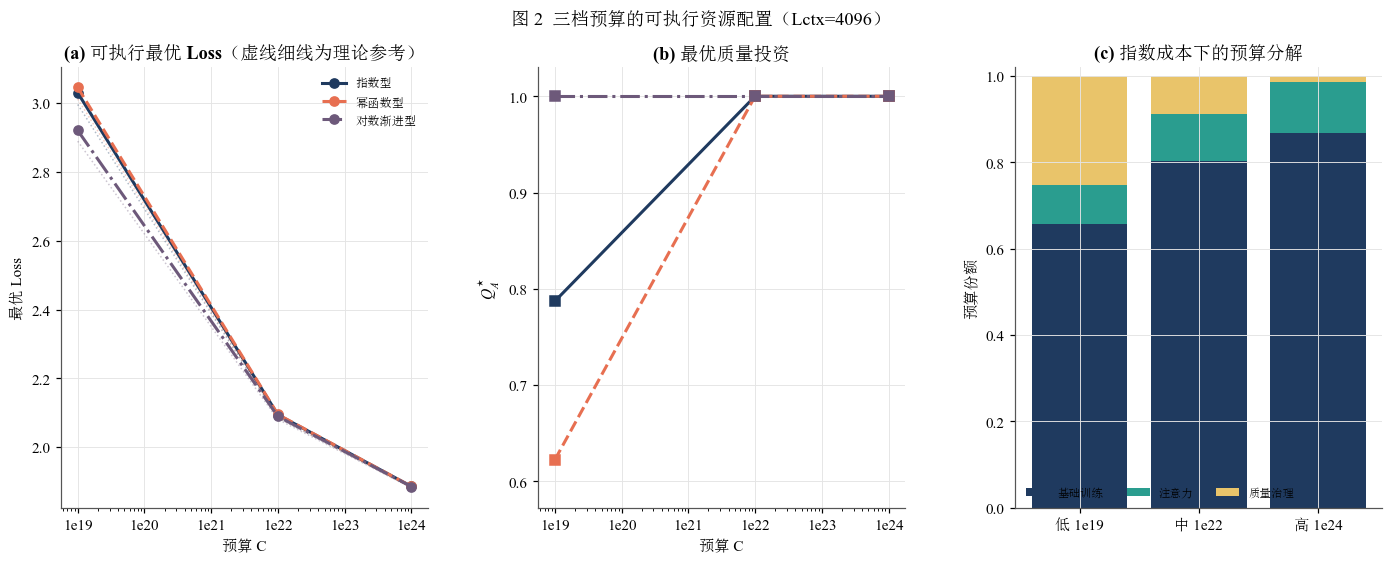

In [35]:
# ============ 3. 三档预算 × 三类成本：可执行策略 + 理论参考 ============
rows = []
for cost in COSTS:
    for C in BUDGETS:
        s = solve_executable(C,L_DEFAULT,cost)
        o = solve_reference_oracle(C,L_DEFAULT,cost)
        rows.append({
            '成本函数':cost,'C':C,
            '可执行配比':s['p_name'],
            'N_B':s['N']/1e9,'D_B':s['D']/1e9,'D_over_N':s['D_over_N'],
            'Q_A':s['Q'],'Q_B':s['Q_B'],'Loss':s['loss'],'regime':s['regime'],
            's_train':s['s_train'],'s_attn':s['s_attn'],'s_Q':s['s_Q'],
            'reference_loss':o['loss'],
            'evidence_gap':s['loss']-o['loss'],
            'evidence_gap_%':100*(s['loss']-o['loss'])/o['loss'],
            'certificate':s['certificate']
        })

RES3 = pd.DataFrame(rows)
RES3.to_csv(TAB/'optimal_executable_allocation_three_budgets.csv',index=False,encoding='utf-8-sig')
display(RES3)

print('\n自动结果摘要：')
for cost in COSTS:
    sub = RES3[RES3['成本函数']==cost].sort_values('C')
    print(
        f"{cost}: 配比={list(sub['可执行配比'])}; "
        f"体制={' → '.join(sub.regime)}; "
        f"Loss={', '.join(f'{x:.4f}' for x in sub.Loss)}"
    )

# 图 2：沿用原版多面板风格
fig = plt.figure(figsize=(15.5,5.2))
gs = gridspec.GridSpec(1,3,wspace=.30)

ax = fig.add_subplot(gs[0])
for cost in COSTS:
    sub = RES3[RES3['成本函数']==cost].sort_values('C')
    ax.plot(sub.C,sub.Loss,marker='o',lw=2.0,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
    ax.plot(sub.C,sub.reference_loss,lw=1.0,color=COL_COST[cost],alpha=.35,ls=':')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('最优 Loss')
ax.set_title('(a) 可执行最优 Loss（虚线细线为理论参考）')
ax.legend(frameon=False,fontsize=8)

ax = fig.add_subplot(gs[1])
for cost in COSTS:
    sub = RES3[RES3['成本函数']==cost].sort_values('C')
    ax.plot(sub.C,sub.Q_A,marker='s',lw=2.0,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel(r'$Q_A^\star$')
ax.set_ylim(max(0,EXEC.Q0_A.min()-.05),1.03)
ax.set_title('(b) 最优质量投资')

ax = fig.add_subplot(gs[2])
sub = RES3[RES3['成本函数']=='指数型'].sort_values('C')
x = np.arange(len(sub))
ax.bar(x,sub.s_train,label='基础训练',color=C_NAVY)
ax.bar(x,sub.s_attn,bottom=sub.s_train,label='注意力',color=C_TEAL)
ax.bar(x,sub.s_Q,bottom=sub.s_train+sub.s_attn,label='质量治理',color=C_GOLD)
ax.set_xticks(x); ax.set_xticklabels([BUD_LAB[c] for c in sub.C])
ax.set_ylim(0,1.02); ax.set_ylabel('预算份额')
ax.set_title('(c) 指数成本下的预算分解')
ax.legend(frameon=False,ncol=3,fontsize=7.5)

fig.suptitle(f'图 2  三档预算的可执行资源配置（Lctx={L_DEFAULT}）',fontsize=12)
savefig('fig02_three_budget_executable.png'); plt.show()


## 4. 连续预算、结构性转移与“参考下界”差距

三档预算只能给出截面。为识别真正的结构变化，在

\[
C\in[10^{16},10^{27}]
\]

上使用事件驱动 continuation 跟踪**可执行策略**。若存在多个可执行配比，状态签名定义为

\[
(\mathbf p^\star,\mathrm{R0/R1/R2}).
\]

相邻节点出现状态变化或 \(Q_A^\star\) 快速变化时，自适应插入预算点，再用 KKT 边界或 value crossing 精确定位。

\(p_{\rm ref}\) 只在同一预算上计算参考下界，不参与状态切换；因此图中的“证据差距”

\[
\Delta_{\rm evidence}(C)
=
L_{\rm exec}^\star(C)-L_{\rm ref}^\star(C)
\]

是独立诊断量，不会反向改变可执行决策。


continuation 完成，用时 24.33s


,成本函数,L_ctx,C_transition,from_p,from_regime,to_p,to_regime,定位机制
0,指数型,4096,4.00736e+18,p_risk,R0,p_risk,R1,KKT rho(Q0)=1
1,指数型,4096,6.88481e+19,p_risk,R1,p_risk,R2,state bisection
2,幂函数型,4096,1.70139e+19,p_risk,R0,p_risk,R1,KKT rho(Q0)=1
3,幂函数型,4096,1.9505e+19,p_risk,R1,p_risk,R2,state bisection
4,对数渐进型,4096,5.122e+17,p_risk,R0,p_risk,R2,R0/R2 branch crossing


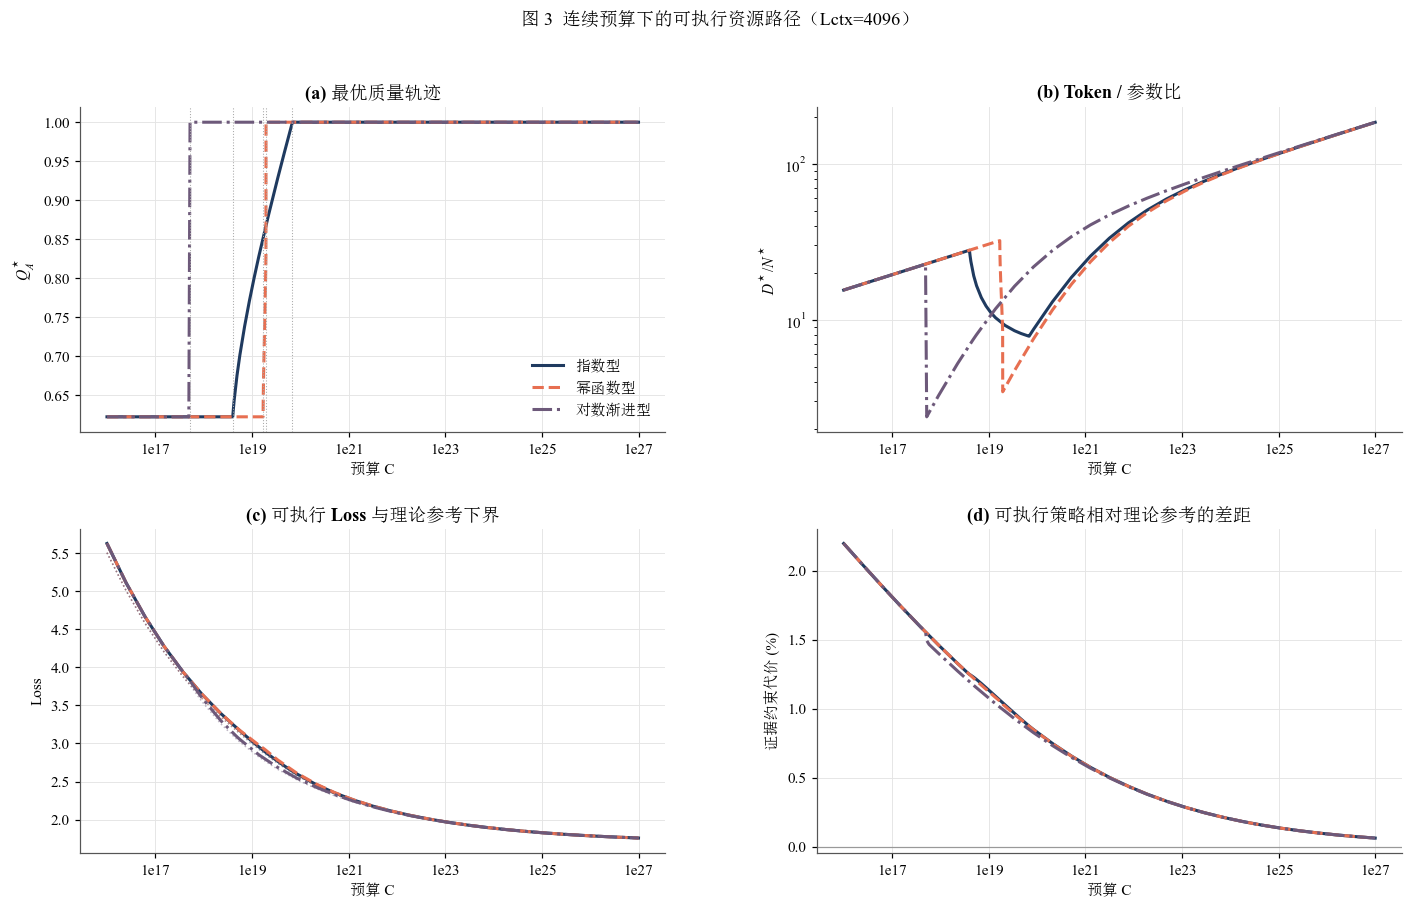

In [36]:
# ============ 4. continuation + 精确转移 ============
def _rho_boundary_roots_for_p(L,cost,p_name,qside='Q0',th=None,kappa=None,eta=None,lo=15,hi=28):
    info = EXEC_INFO[p_name]
    qfix = info['Q0_A'] if qside == 'Q0' else 1.0

    def f(lc):
        s = _fixedQ_kkt(10**lc,L,cost,qfix,info['Q0_A'],th,kappa,info['psi_p0'],eta)
        return np.log(max(s['rho'],1e-300))

    grid = np.linspace(lo,hi,55)
    vals = np.array([f(x) for x in grid])
    roots = []
    for i in range(len(grid)-1):
        if np.isfinite(vals[i]) and np.isfinite(vals[i+1]) and vals[i]*vals[i+1] < 0:
            roots.append(10**brentq(f,grid[i],grid[i+1],xtol=1e-8,rtol=1e-9))
    return roots

def _state_sig(s):
    return (s['p_name'],s['regime'])

def adaptive_budget_scan(L,cost,th=None,kappa=None,eta=None,
                         log_lo=16,log_hi=27,base_n=29,max_depth=4,
                         gamma=None,c_q=None):
    logs = set(np.linspace(log_lo,log_hi,base_n).tolist())

    for p in EXEC_INFO:
        for side in ('Q0','Q1'):
            roots = _rho_boundary_roots_for_p(
                L,cost,p,'Q0' if side=='Q0' else 'Q1',
                th,kappa,eta,log_lo-1,log_hi+1
            )
            for C0_ in roots:
                lc = np.log10(C0_)
                if log_lo < lc < log_hi:
                    for d in (-.03,0,.03):
                        logs.add(float(np.clip(lc+d,log_lo,log_hi)))

    cache = {}
    def get(lc):
        key = round(float(lc),12)
        if key not in cache:
            cache[key] = solve_executable(
                10**lc,L,cost,th,kappa,eta,nscan=35,gamma=gamma,c_q=c_q
            )
        return cache[key]

    for _ in range(max_depth):
        ls = sorted(logs)
        add = []
        for a,b in zip(ls[:-1],ls[1:]):
            sa,sb = get(a),get(b)
            need = (
                _state_sig(sa) != _state_sig(sb)
                or abs(sa['Q']-sb['Q']) > .055
                or ((b-a)>.35 and (sa['regime']=='R1' or sb['regime']=='R1'))
            )
            if need and b-a > 2e-3:
                add.append((a+b)/2)
        if not add:
            break
        logs.update(add)

    rows = []
    for lc in sorted(logs):
        s = get(lc)
        o = solve_reference_oracle(10**lc,L,cost,th,kappa,eta,nscan=35,gamma=gamma,c_q=c_q)
        rows.append({
            'log10C':lc,'C':10**lc,
            **{k:s[k] for k in ('N','D','Q','Q_B','loss','regime','p_name','s_train','s_attn','s_Q','certificate')},
            'reference_loss':o['loss'],
            'evidence_gap':s['loss']-o['loss']
        })

    df = pd.DataFrame(rows).sort_values('C').reset_index(drop=True)
    lnC = np.log(df.C.values)
    df['D_over_N'] = df.D/df.N
    df['eps_N'] = np.gradient(np.log(df.N.values),lnC)
    df['eps_D'] = np.gradient(np.log(df.D.values),lnC)
    df['eps_Q'] = np.gradient(df.Q.values,lnC)
    return df

def refine_transition(Ca,Cb,L,cost,state_a,state_b,th=None,kappa=None,eta=None):
    pa,ra = state_a
    pb,rb = state_b
    la,lb = np.log10(Ca),np.log10(Cb)

    if pa != pb:
        def gap(lc):
            ia,ib = EXEC_INFO[pa],EXEC_INFO[pb]
            a = solve_alloc_certified(10**lc,L,cost,ia['Q0_A'],th,kappa,ia['psi_p0'],eta)['loss']
            b = solve_alloc_certified(10**lc,L,cost,ib['Q0_A'],th,kappa,ib['psi_p0'],eta)['loss']
            return a-b
        try:
            return 10**brentq(gap,la,lb,xtol=1e-8,rtol=1e-9),'executable-mixture value crossing'
        except ValueError:
            pass

    if pa == pb:
        info = EXEC_INFO[pa]
        if {ra,rb} == {'R0','R1'}:
            def f(lc):
                s = _fixedQ_kkt(10**lc,L,cost,info['Q0_A'],info['Q0_A'],th,kappa,info['psi_p0'],eta)
                return np.log(max(s['rho'],1e-300))
            try:
                return 10**brentq(f,la,lb,xtol=1e-8,rtol=1e-9),'KKT rho(Q0)=1'
            except ValueError:
                pass

        if {ra,rb} == {'R1','R2'}:
            def f(lc):
                s = _fixedQ_kkt(10**lc,L,cost,1.0,info['Q0_A'],th,kappa,info['psi_p0'],eta)
                return np.log(max(s['rho'],1e-300))
            try:
                return 10**brentq(f,la,lb,xtol=1e-8,rtol=1e-9),'KKT rho(1)=1'
            except ValueError:
                pass

        if {ra,rb} == {'R0','R2'}:
            def gap(lc):
                c = 10**lc
                a = _fixedQ_kkt(c,L,cost,info['Q0_A'],info['Q0_A'],th,kappa,info['psi_p0'],eta)['loss']
                b = _fixedQ_kkt(c,L,cost,1.0,info['Q0_A'],th,kappa,info['psi_p0'],eta)['loss']
                return a-b
            try:
                return 10**brentq(gap,la,lb,xtol=1e-8,rtol=1e-9),'R0/R2 branch crossing'
            except ValueError:
                pass

    left,right = la,lb
    sleft = state_a
    for _ in range(50):
        mid = (left+right)/2
        sm = _state_sig(solve_executable(10**mid,L,cost,th,kappa,eta,nscan=35))
        if sm == sleft:
            left = mid
        else:
            right = mid
    return 10**((left+right)/2),'state bisection'

def extract_transitions(df,L,cost,th=None,kappa=None,eta=None):
    rows = []
    for i in range(1,len(df)):
        a,b = df.iloc[i-1],df.iloc[i]
        sa,sb = (a.p_name,a.regime),(b.p_name,b.regime)
        if sa != sb:
            Cstar,typ = refine_transition(a.C,b.C,L,cost,sa,sb,th,kappa,eta)
            rows.append({
                '成本函数':cost,'L_ctx':L,'C_transition':Cstar,
                'from_p':sa[0],'from_regime':sa[1],
                'to_p':sb[0],'to_regime':sb[1],'定位机制':typ
            })
    return pd.DataFrame(rows)

CURVES,TRANS_LIST = {},[]
t0 = time.time()
for cost in COSTS:
    CURVES[cost] = adaptive_budget_scan(L_DEFAULT,cost)
    tr = extract_transitions(CURVES[cost],L_DEFAULT,cost)
    TRANS_LIST.append(tr)
    CURVES[cost].to_csv(TAB/f'budget_continuation_{cost}.csv',index=False,encoding='utf-8-sig')

TRANS = pd.concat([x for x in TRANS_LIST if len(x)],ignore_index=True) if any(len(x) for x in TRANS_LIST) else pd.DataFrame()
TRANS.to_csv(TAB/'structural_transition_points.csv',index=False,encoding='utf-8-sig')
print(f'continuation 完成，用时 {time.time()-t0:.2f}s')
display(TRANS)

# 图 3：原版式多面板连续轨迹
fig = plt.figure(figsize=(15.5,8.8))
gs = gridspec.GridSpec(2,2,wspace=.26,hspace=.30)

ax = fig.add_subplot(gs[0,0])
for cost in COSTS:
    cv = CURVES[cost]
    ax.plot(cv.C,cv.Q,lw=2,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
for _,r in TRANS.iterrows():
    ax.axvline(r.C_transition,color='#AAAAAA',ls=':',lw=.7)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel(r'$Q_A^\star$')
ax.set_title('(a) 最优质量轨迹'); ax.legend(frameon=False)

ax = fig.add_subplot(gs[0,1])
for cost in COSTS:
    cv = CURVES[cost]
    ax.plot(cv.C,cv.D_over_N,lw=2,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel(r'$D^\star/N^\star$')
ax.set_title('(b) Token / 参数比')

ax = fig.add_subplot(gs[1,0])
for cost in COSTS:
    cv = CURVES[cost]
    ax.plot(cv.C,cv.loss,lw=2,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
    ax.plot(cv.C,cv.reference_loss,lw=1,color=COL_COST[cost],ls=':',alpha=.45)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('Loss')
ax.set_title('(c) 可执行 Loss 与理论参考下界')

ax = fig.add_subplot(gs[1,1])
for cost in COSTS:
    cv = CURVES[cost]
    ax.plot(cv.C,100*cv.evidence_gap/cv.reference_loss,lw=2,color=COL_COST[cost],ls=LS_COST[cost],label=cost)
ax.axhline(0,color='#999999',lw=.8)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('证据约束代价 (%)')
ax.set_title('(d) 可执行策略相对理论参考的差距')

fig.suptitle(f'图 3  连续预算下的可执行资源路径（Lctx={L_DEFAULT}）',fontsize=12)
savefig('fig03_budget_continuation.png'); plt.show()


## 5. 成本函数选择与预算—上下文相位图

不同 \(g(Q)\) 的主要作用是改变：

1. 质量投资的边际价格 \(g'(Q_A)\)；
2. 从 \(Q_{0,A}\) 提升到某一 \(Q_A\) 的累计资源占用 \(\Delta g\)；
3. 因而改变 R0、R1、R2 的出现区间和转移预算。

在默认 \(L_{ctx}\) 下先报告三类成本的精确转移点；随后对 C7 全部上下文长度求指数型成本的二维相位图。相位图的颜色只表示 R0/R1/R2，有效配比切换若发生则由边界表单独记录，避免把“理论参考”误画成可执行最优区域。


,成本函数,类型,C1,C2,C_jump
0,指数型,R1 连续窗口,4.00736e+18,6.88481e+19,NaN
1,幂函数型,R1 连续窗口,1.70139e+19,1.9505e+19,NaN
2,对数渐进型,R0→R2 分支跳变,NaN,NaN,5.122e+17


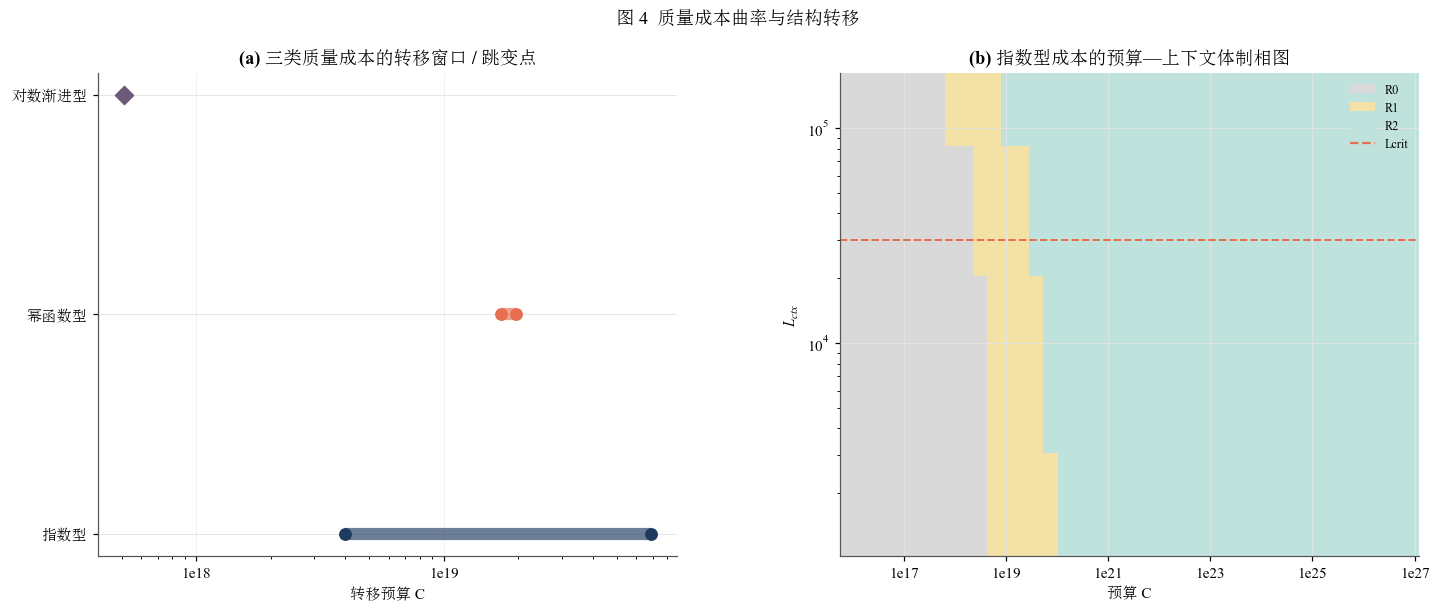

In [37]:
# ============ 5. 成本函数的转移窗口 + C×Lctx 相位图 ============
window_rows = []
for cost in COSTS:
    tr = TRANS[TRANS['成本函数']==cost].sort_values('C_transition') if len(TRANS) else pd.DataFrame()
    if len(tr)==0:
        window_rows.append({'成本函数':cost,'类型':'区间内无转移','C1':np.nan,'C2':np.nan,'C_jump':np.nan})
        continue
    r01 = tr[(tr.from_regime=='R0') & (tr.to_regime=='R1')]
    r12 = tr[(tr.from_regime=='R1') & (tr.to_regime=='R2')]
    r02 = tr[(tr.from_regime=='R0') & (tr.to_regime=='R2')]
    if len(r01) and len(r12):
        window_rows.append({
            '成本函数':cost,'类型':'R1 连续窗口',
            'C1':float(r01.C_transition.iloc[0]),
            'C2':float(r12.C_transition.iloc[0]),
            'C_jump':np.nan
        })
    elif len(r02):
        window_rows.append({
            '成本函数':cost,'类型':'R0→R2 分支跳变',
            'C1':np.nan,'C2':np.nan,'C_jump':float(r02.C_transition.iloc[0])
        })
    else:
        window_rows.append({
            '成本函数':cost,'类型':'复合/配比转移',
            'C1':np.nan,'C2':np.nan,'C_jump':float(tr.C_transition.iloc[0])
        })
WINDOW = pd.DataFrame(window_rows)
WINDOW.to_csv(TAB/'transition_windows.csv',index=False,encoding='utf-8-sig')
display(WINDOW)

# 相位图
C_PHASE = np.logspace(16,27,41)
phase_rows = []
for L_ in FEAS:
    for C in C_PHASE:
        s = solve_executable(C,L_,'指数型',nscan=31)
        phase_rows.append({
            'L_ctx':L_,'C':C,'regime':s['regime'],
            'p_name':s['p_name'],'Q':s['Q'],'loss':s['loss']
        })
PH = pd.DataFrame(phase_rows)
PH.to_csv(TAB/'phase_map_exp.csv',index=False,encoding='utf-8-sig')

reg_map = {'R0':0,'R1':1,'R2':2}
Z = np.array([
    [reg_map[x] for x in PH[PH.L_ctx==L_].sort_values('C').regime]
    for L_ in FEAS
],float)

fig = plt.figure(figsize=(15.5,5.7))
gs = gridspec.GridSpec(1,2,wspace=.28)

ax = fig.add_subplot(gs[0])
for i,cost in enumerate(COSTS):
    r = WINDOW[WINDOW['成本函数']==cost].iloc[0]
    if np.isfinite(r.C1) and np.isfinite(r.C2):
        ax.hlines(i,r.C1,r.C2,color=COL_COST[cost],lw=8,alpha=.65)
        ax.scatter([r.C1,r.C2],[i,i],color=COL_COST[cost],s=55,zorder=3)
    elif np.isfinite(r.C_jump):
        ax.scatter(r.C_jump,i,marker='D',color=COL_COST[cost],s=70,zorder=3)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_yticks(range(len(COSTS))); ax.set_yticklabels(COSTS)
ax.set_xlabel('转移预算 C'); ax.set_title('(a) 三类质量成本的转移窗口 / 跳变点')
ax.grid(axis='x',alpha=.5)

ax = fig.add_subplot(gs[1])
X,Y = np.meshgrid(C_PHASE,np.array(FEAS,float))
cmap_reg = mpl.colors.ListedColormap([COL_REG['R0'],COL_REG['R1'],COL_REG['R2']])
norm_reg = mpl.colors.BoundaryNorm([-.5,.5,1.5,2.5],cmap_reg.N)
ax.pcolormesh(X,Y,Z,shading='nearest',cmap=cmap_reg,norm=norm_reg)
ax.axhline(L_CRIT,color=C_CORAL,ls='--',lw=1.3,label=f'Lcrit={L_CRIT:.0f}')
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel(r'$L_{ctx}$')
ax.set_title('(b) 指数型成本的预算—上下文体制相图')
ax.legend(handles=[
    Patch(facecolor=COL_REG['R0'],label='R0'),
    Patch(facecolor=COL_REG['R1'],label='R1'),
    Patch(facecolor=COL_REG['R2'],label='R2'),
    Line2D([0],[0],color=C_CORAL,ls='--',label='Lcrit')
],frameon=False,fontsize=8)

fig.suptitle('图 4  质量成本曲率与结构转移',fontsize=12)
savefig('fig04_transition_and_phase.png'); plt.show()


## 6. 上下文长度与资源弹性敏感性

上下文长度通过

\[
c_N=6+\eta L_{ctx}
\]

提高每单位 \(ND\) 的计算价格，因此不会改变质量收益函数本身，却会挤压训练可用预算。对 C7 的全部真实可行值重新求三档预算下的最优配置，并报告 Loss、\(Q_A^\star\)、三类预算份额与体制变化。

为量化跨预算的边际资源重分配，定义

\[
\varepsilon_N=\frac{d\ln N^\star}{d\ln C},\qquad
\varepsilon_D=\frac{d\ln D^\star}{d\ln C},\qquad
\varepsilon_Q=\frac{dQ_A^\star}{d\ln C}.
\]

转移点附近的一阶导数可能不连续，因此弹性图主要用于观察稳定区间，不把边界尖峰解释成长期趋势。


,L_ctx,C,p_star,N_B,D_B,Q_A,Loss,regime,s_train,s_attn,s_Q
0,2048,1e+19,p_risk,0.312025,3.78696,0.77711,3.01886,R1,0.708976,0.0483994,0.242625
1,2048,1e+22,p_risk,5.67571,250.033,1,2.09034,R2,0.851467,0.0581268,0.0904067
2,2048,1e+24,p_risk,41.2135,3734.44,1,1.88415,R2,0.923456,0.0630412,0.013503
3,4096,1e+19,p_risk,0.307753,3.56565,0.78707,3.02967,R1,0.658403,0.089894,0.251703
4,4096,1e+22,p_risk,5.50163,243.117,1,2.09399,R2,0.802523,0.109571,0.0879062
5,4096,1e+24,p_risk,40.0569,3613.09,1,1.886,R2,0.868374,0.118562,0.0130642
6,8192,1e+19,p_risk,0.299401,3.20677,0.804713,3.04948,R1,0.576065,0.157304,0.26663
7,8192,1e+22,p_risk,5.19763,230.854,1,2.10076,R2,0.719937,0.196591,0.0834723
8,8192,1e+24,p_risk,38.0238,3400.7,1,1.88944,R2,0.775846,0.211858,0.0122963
9,30000,1e+19,p_risk,0.262923,2.18287,0.869566,3.12909,R1,0.344356,0.344356,0.311288


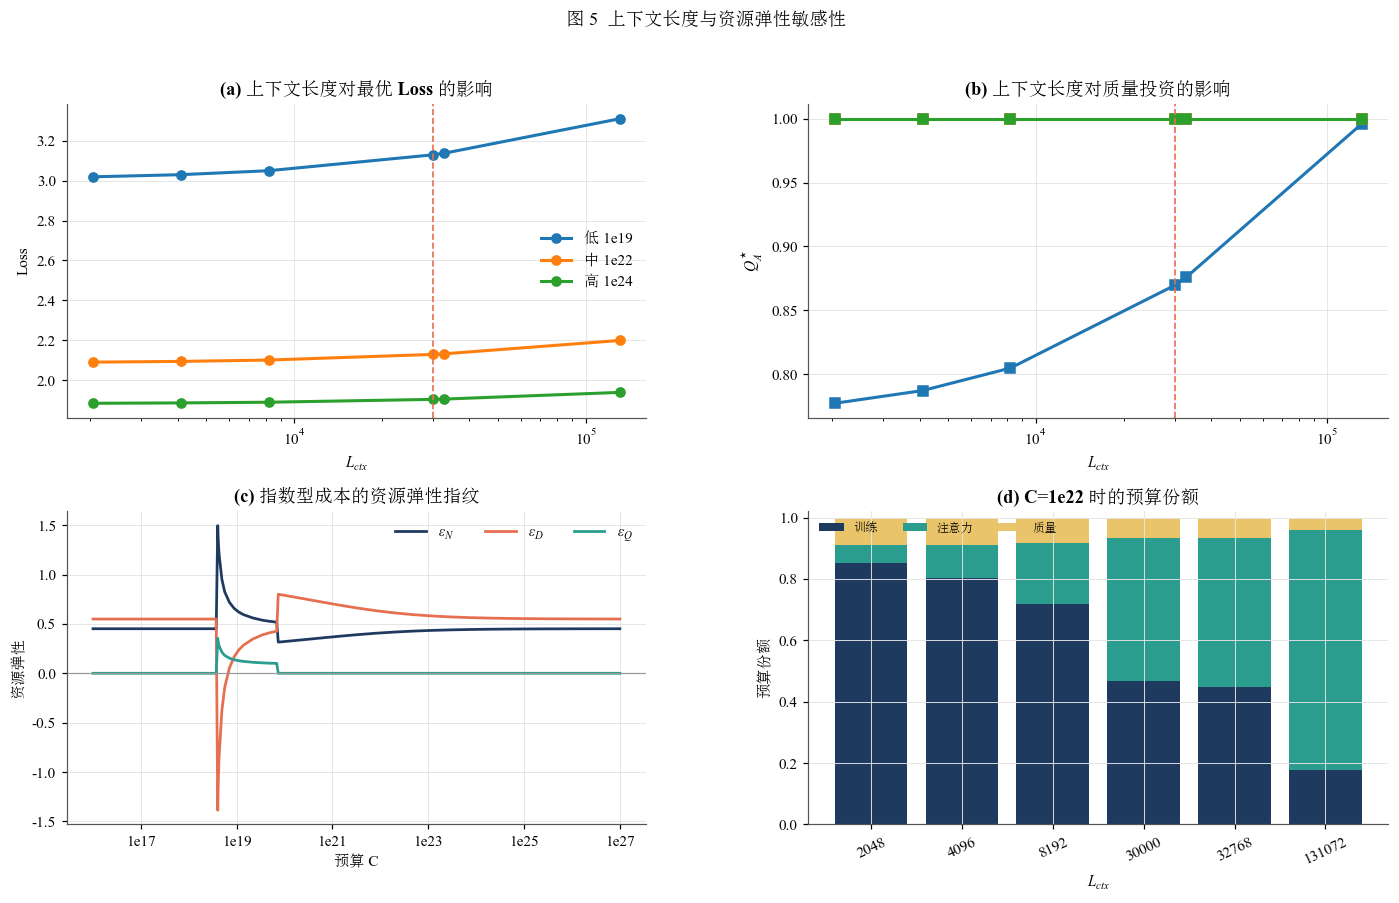

In [38]:
# ============ 6. Lctx 敏感性 + 资源弹性 ============
sens_rows = []
for L_ in L_ALL:
    for C in BUDGETS:
        s = solve_executable(C,L_,'指数型')
        sens_rows.append({
            'L_ctx':L_,'C':C,'p_star':s['p_name'],
            'N_B':s['N']/1e9,'D_B':s['D']/1e9,'Q_A':s['Q'],'Loss':s['loss'],
            'regime':s['regime'],'s_train':s['s_train'],'s_attn':s['s_attn'],'s_Q':s['s_Q']
        })
SENS_L = pd.DataFrame(sens_rows)
SENS_L.to_csv(TAB/'sensitivity_context_length.csv',index=False,encoding='utf-8-sig')
display(SENS_L)

cv = CURVES['指数型'].copy()
fig = plt.figure(figsize=(15.5,8.5))
gs = gridspec.GridSpec(2,2,wspace=.28,hspace=.30)

ax = fig.add_subplot(gs[0,0])
for C in BUDGETS:
    sub = SENS_L[SENS_L.C==C].sort_values('L_ctx')
    ax.plot(sub.L_ctx,sub.Loss,marker='o',lw=2,label=BUD_LAB[C])
ax.axvline(L_CRIT,color=C_CORAL,ls='--',lw=1.1)
ax.set_xscale('log'); ax.set_xlabel(r'$L_{ctx}$'); ax.set_ylabel('Loss')
ax.set_title('(a) 上下文长度对最优 Loss 的影响'); ax.legend(frameon=False)

ax = fig.add_subplot(gs[0,1])
for C in BUDGETS:
    sub = SENS_L[SENS_L.C==C].sort_values('L_ctx')
    ax.plot(sub.L_ctx,sub.Q_A,marker='s',lw=2,label=BUD_LAB[C])
ax.axvline(L_CRIT,color=C_CORAL,ls='--',lw=1.1)
ax.set_xscale('log'); ax.set_xlabel(r'$L_{ctx}$'); ax.set_ylabel(r'$Q_A^\star$')
ax.set_title('(b) 上下文长度对质量投资的影响')

ax = fig.add_subplot(gs[1,0])
ax.plot(cv.C,cv.eps_N,lw=1.8,color=C_NAVY,label=r'$\epsilon_N$')
ax.plot(cv.C,cv.eps_D,lw=1.8,color=C_CORAL,label=r'$\epsilon_D$')
ax.plot(cv.C,cv.eps_Q,lw=1.8,color=C_TEAL,label=r'$\epsilon_Q$')
ax.axhline(0,color='#999999',lw=.8)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('资源弹性')
ax.set_title('(c) 指数型成本的资源弹性指纹'); ax.legend(frameon=False,ncol=3)

ax = fig.add_subplot(gs[1,1])
sub = SENS_L[SENS_L.C==1e22].sort_values('L_ctx')
x = np.arange(len(sub))
ax.bar(x,sub.s_train,label='训练',color=C_NAVY)
ax.bar(x,sub.s_attn,bottom=sub.s_train,label='注意力',color=C_TEAL)
ax.bar(x,sub.s_Q,bottom=sub.s_train+sub.s_attn,label='质量',color=C_GOLD)
ax.set_xticks(x); ax.set_xticklabels([str(int(v)) for v in sub.L_ctx],rotation=25)
ax.set_ylim(0,1.02); ax.set_ylabel('预算份额'); ax.set_xlabel(r'$L_{ctx}$')
ax.set_title('(d) C=1e22 时的预算份额')
ax.legend(frameon=False,ncol=3,fontsize=8)

fig.suptitle('图 5  上下文长度与资源弹性敏感性',fontsize=12)
savefig('fig05_context_and_elasticity.png'); plt.show()


## 7. 不确定性传播：联合端点，而不是单因素“假鲁棒”

问题二已经明确 \((\alpha,\beta)\) 存在跨族不确定性，而且该项会直接改变 compute-optimal 的 \(N^\star,D^\star\)。因此本问把不确定性分为两层：

### 7.1 完整 Scaling 场景

若问题二接口已经导出完整、经过正性重标定的

\[
(E,A,\alpha,B,\beta)
\]

场景，则直接读取，绝不在问题三重新拟合。代码支持 `scaling_scenarios` / `exponent_scenarios` 或同名 sidecar JSON。

若接口尚未导出完整参数组，则本问**不会**只改 \(\alpha,\beta\) 而固定 \(E,A,B\)；此时鲁棒结论明确限定为“质量/配比桥参数 stress test”，不能声称覆盖完整 Scaling Law 不确定性。

### 7.2 联合角点

对

\[
\kappa\in\{\kappa_L,\kappa_H\},\quad
\gamma_p\in\{\gamma_L,\gamma_H\},\quad
c_Q\in\{c_L,c_H\}
\]

采用 \(2^3=8\) 个联合角点，而不是一次只改一个参数。若完整 Scaling 场景可用，再与这些角点做笛卡尔积。

### 7.3 minimax-regret

对情景 \(s\)，令 \(L_s^\star\) 为该情景下可执行集合的最优值，定义

\[
r_s(x)
=
\frac{L_s(x)-L_s^\star}
{L_s^\star-E_s+\epsilon}.
\]

在由各情景最优解构成的候选决策集中求

\[
x_{\rm rob}
=
\arg\min_x\max_s r_s(x).
\]

若完整 Scaling 场景不可用，`x_rob` 仅作为“桥参数鲁棒候选”，最终主推荐仍以名义可执行最优为准，并在输出中显式记录 `uncertainty_scope`。


不确定性覆盖范围: bridge_joint_box_only__scaling_scenarios_not_exported_by_Q2
完整 Scaling 参数组: ['nominal']
联合情景数量: 9


,C,方法,p,Q,max_regret,mean_regret,uncertainty_scope
0,1e+19,nominal executable,p_risk,0.78707,0.00833401,0.00465756,bridge_joint_box_only__scaling_scenarios_not_e...
1,1e+19,minimax-regret candidate,p_risk,0.78707,0.00833401,0.00465756,bridge_joint_box_only__scaling_scenarios_not_e...
2,1e+22,nominal executable,p_risk,1,6.1716e-08,4.00321e-08,bridge_joint_box_only__scaling_scenarios_not_e...
3,1e+22,minimax-regret candidate,p_risk,1,6.1716e-08,4.00321e-08,bridge_joint_box_only__scaling_scenarios_not_e...
4,1e+24,nominal executable,p_risk,1,2.72065e-08,1.57968e-08,bridge_joint_box_only__scaling_scenarios_not_e...
5,1e+24,minimax-regret candidate,p_risk,1,2.72065e-08,1.57968e-08,bridge_joint_box_only__scaling_scenarios_not_e...


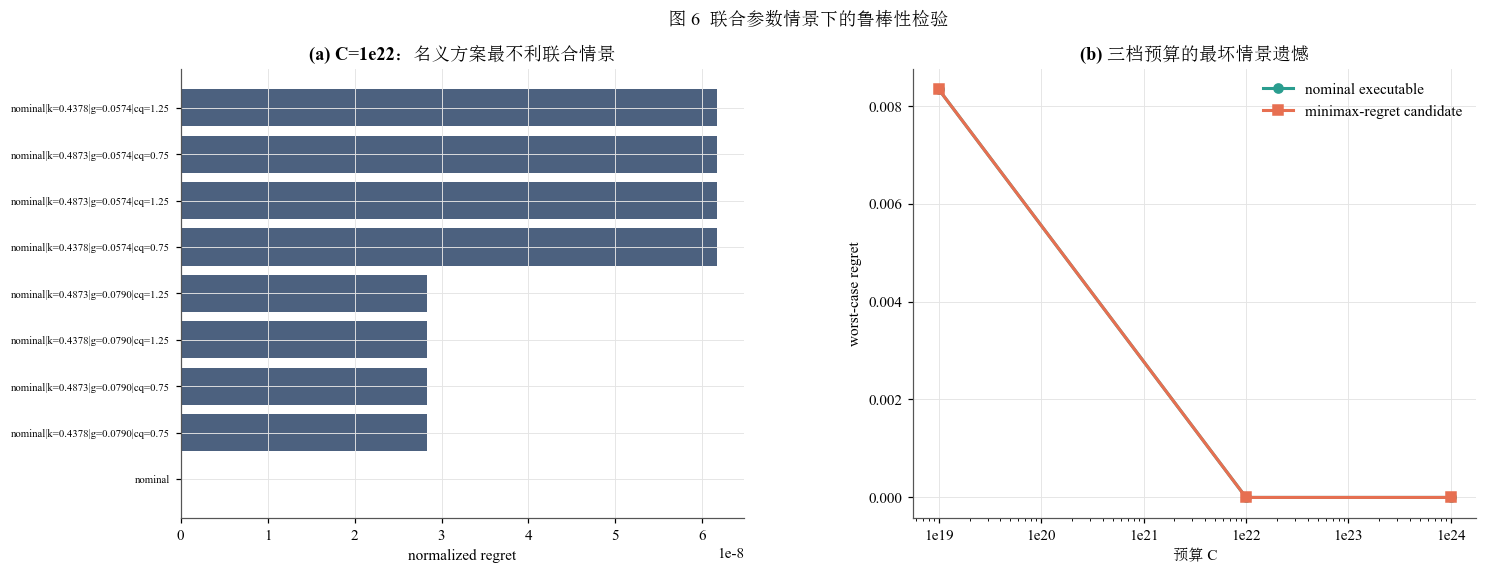

In [39]:
# ============ 7. 联合不确定性情景 + minimax-regret ============
REQ_TH = {'E','A','alpha','B','beta'}

def collect_full_scaling_scenarios():
    found = {}

    def scan(obj,prefix=''):
        if isinstance(obj,dict):
            if REQ_TH.issubset(obj.keys()):
                try:
                    th = {k:float(obj[k]) for k in REQ_TH}
                    if th['E']>=0 and th['A']>0 and th['B']>0 and th['alpha']>0 and th['beta']>0:
                        found[prefix or 'scenario'] = th
                except Exception:
                    pass
            for k,v in obj.items():
                if k in {'scaling_scenarios','exponent_scenarios','scenarios'} or isinstance(v,dict):
                    scan(v,f'{prefix}.{k}' if prefix else str(k))

    # 先扫 Q2 handoff
    scan(Q2)

    # 再扫 sidecar（如果问题二后来补导出）
    for fn in ['scaling_scenarios.json','exponent_scenarios.json','positive_recalibrated_scaling_scenarios.json']:
        p = F_ROOT/'output_q2'/'tables'/fn
        if p.exists():
            try:
                scan(json.loads(p.read_text(encoding='utf-8')),fn)
            except Exception:
                pass

    # 去掉与 nominal 几乎相同的重复场景
    uniq = {'nominal':TH}
    sigs = {tuple(round(TH[k],12) for k in ('E','A','alpha','B','beta'))}
    for name,th in found.items():
        sig = tuple(round(th[k],12) for k in ('E','A','alpha','B','beta'))
        if sig not in sigs:
            sigs.add(sig); uniq[name]=th
    return uniq

SCALING_SCEN = collect_full_scaling_scenarios()
HAS_FULL_SCALING_UNC = len(SCALING_SCEN) > 1

k_vals = sorted(set([float(KAPPA_CI[0]),float(KAPPA_CI[1])]))
g_vals = sorted(set([float(GAMMA_CI[0]),float(GAMMA_CI[-1])]))
cq_vals = sorted(set([float(min(CQ_SCENARIOS)),float(max(CQ_SCENARIOS))]))

SCENARIOS = []
for th_name,ths in SCALING_SCEN.items():
    for kv,gv,cqv in itertools.product(k_vals,g_vals,cq_vals):
        SCENARIOS.append({
            'name':f'{th_name}|k={kv:.4f}|g={gv:.4f}|cq={cqv:.2f}',
            'th_name':th_name,'th':ths,'kappa':kv,'gamma':gv,'c_q':cqv
        })

# 名义点额外加入
SCENARIOS.append({
    'name':'nominal','th_name':'nominal','th':TH,
    'kappa':KAPPA,'gamma':GAMMA_P,'c_q':CQ_NOMINAL
})

UNCERTAINTY_SCOPE = (
    'full_scaling_x_bridge_joint_box'
    if HAS_FULL_SCALING_UNC
    else 'bridge_joint_box_only__scaling_scenarios_not_exported_by_Q2'
)

print('不确定性覆盖范围:',UNCERTAINTY_SCOPE)
print('完整 Scaling 参数组:',list(SCALING_SCEN.keys()))
print('联合情景数量:',len(SCENARIOS))
if not HAS_FULL_SCALING_UNC:
    warnings.warn(
        '问题二当前 handoff 未导出完整的正性重标定 Scaling 场景。'
        '本节只做 κ×γ_p×c_Q 的联合角点 stress test；'
        '不把结果表述为完整 Scaling Law 鲁棒性。'
    )

def eval_decision(x,sc):
    return float(L_gen(
        x['N'],x['D'],x['Q'],x['Q0_A'],
        th=sc['th'],kappa=sc['kappa'],psi_p0=x['psi_p0'],
        gamma=sc['gamma'],c_q=sc['c_q']
    ))

def robust_minimax_regret(C,L,cost):
    scen_opt = []
    for sc in SCENARIOS:
        z = solve_executable(
            C,L,cost,th=sc['th'],kappa=sc['kappa'],
            gamma=sc['gamma'],c_q=sc['c_q'],nscan=71
        )
        z['scenario_origin'] = sc['name']
        scen_opt.append(z)

    nominal = solve_executable(C,L,cost)
    candidates = scen_opt + [dict(nominal,scenario_origin='nominal_solution')]

    optloss = {z['scenario_origin']:z['loss'] for z in scen_opt}
    # 场景可能同名 nominal；用顺序重新建立
    scenario_opt_loss = {
        sc['name']: next(z['loss'] for z in scen_opt if z['scenario_origin']==sc['name'])
        for sc in SCENARIOS
    }

    rows = []
    for j,x in enumerate(candidates):
        regrets = []
        for sc in SCENARIOS:
            ls = eval_decision(x,sc)
            lstar = scenario_opt_loss[sc['name']]
            denom = max(lstar - sc['th']['E'],1e-12)
            regrets.append((ls-lstar)/denom)
        rows.append({
            'idx':j,'max_regret':max(regrets),'mean_regret':float(np.mean(regrets)),
            'regrets':regrets
        })

    best = min(rows,key=lambda r:(r['max_regret'],r['mean_regret']))
    x = candidates[best['idx']].copy()
    x.update({
        'max_regret':best['max_regret'],'mean_regret':best['mean_regret'],
        'uncertainty_scope':UNCERTAINTY_SCOPE
    })
    return x,scen_opt

ROB_ROWS = []
for C in BUDGETS:
    rob,opts = robust_minimax_regret(C,L_DEFAULT,'指数型')
    nom = solve_executable(C,L_DEFAULT,'指数型')

    # 名义解在所有情景的 regret
    scene_opt_loss = {
        sc['name']: next(z['loss'] for z in opts if z['scenario_origin']==sc['name'])
        for sc in SCENARIOS
    }
    regs = []
    for sc in SCENARIOS:
        ls = eval_decision(nom,sc)
        denom = max(scene_opt_loss[sc['name']]-sc['th']['E'],1e-12)
        regs.append((ls-scene_opt_loss[sc['name']])/denom)

    ROB_ROWS.append({
        'C':C,'方法':'nominal executable','p':nom['p_name'],'Q':nom['Q'],
        'max_regret':max(regs),'mean_regret':float(np.mean(regs)),
        'uncertainty_scope':UNCERTAINTY_SCOPE
    })
    ROB_ROWS.append({
        'C':C,'方法':'minimax-regret candidate','p':rob['p_name'],'Q':rob['Q'],
        'max_regret':rob['max_regret'],'mean_regret':rob['mean_regret'],
        'uncertainty_scope':UNCERTAINTY_SCOPE
    })

ROB = pd.DataFrame(ROB_ROWS)
ROB.to_csv(TAB/'joint_uncertainty_minimax_regret.csv',index=False,encoding='utf-8-sig')
display(ROB)

# 图 6：原版风格 horizontal bar + budget comparison
fig = plt.figure(figsize=(15.2,5.3))
gs = gridspec.GridSpec(1,2,wspace=.30)

ax = fig.add_subplot(gs[0])
midC = 1e22
rob_mid,opts_mid = robust_minimax_regret(midC,L_DEFAULT,'指数型')
nom_mid = solve_executable(midC,L_DEFAULT,'指数型')
scene_opt_loss = {
    sc['name']: next(z['loss'] for z in opts_mid if z['scenario_origin']==sc['name'])
    for sc in SCENARIOS
}
vals = []
labs = []
for sc in SCENARIOS:
    denom = max(scene_opt_loss[sc['name']]-sc['th']['E'],1e-12)
    vals.append((eval_decision(nom_mid,sc)-scene_opt_loss[sc['name']])/denom)
    labs.append(sc['name'])
order = np.argsort(vals)
show = order[-min(12,len(order)):]
ax.barh(np.arange(len(show)),np.array(vals)[show],color=C_NAVY,alpha=.80)
ax.set_yticks(np.arange(len(show)))
ax.set_yticklabels(np.array(labs,dtype=object)[show],fontsize=7)
ax.set_xlabel('normalized regret')
ax.set_title('(a) C=1e22：名义方案最不利联合情景')

ax = fig.add_subplot(gs[1])
for method,color,marker in [
    ('nominal executable',C_TEAL,'o'),
    ('minimax-regret candidate',C_CORAL,'s')
]:
    sub = ROB[ROB['方法']==method].sort_values('C')
    ax.plot(sub.C,sub.max_regret,marker=marker,lw=2,color=color,label=method)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10)
ax.set_xlabel('预算 C'); ax.set_ylabel('worst-case regret')
ax.set_title('(b) 三档预算的最坏情景遗憾')
ax.legend(frameon=False)

fig.suptitle('图 6  联合参数情景下的鲁棒性检验',fontsize=12)
savefig('fig06_joint_uncertainty.png'); plt.show()


## 8. 逻辑一致性证书、等效算力与问题四接口

除了 KKT 数值证书，本问额外输出三类**逻辑证书**：

1. `reference_excluded=True`：\(p_{\rm ref}\) 不属于可执行候选集；
2. `quality_neutrality=True`：所有可执行配比均满足
   \[
   \widetilde\psi_Q(Q_{0,A};\mathbf p)=1;
   \]
3. `uncertainty_scope`：明确记录鲁棒分析是否已经包含完整 \((E,A,\alpha,B,\beta)\) 场景。

同时保留质量投资的“等效算力放大倍数”。反事实模型强制

\[
Q_A=Q_{0,A}(\mathbf p),
\]

但仍只在 \(\mathcal P_{exec}\) 中选择配比。若反事实预算 \(C_{eq}\) 才能达到完整模型预算 \(C\) 下的相同 Loss，则

\[
M(C)=\frac{C_{eq}}C.
\]

该指标只衡量“追加质量治理”相对于继续堆算力的替代价值，不把不同配比自带的 \(Q_{0,A}\) 重新算成质量收益。


In [40]:
# ============ 8. 逻辑证书 + 等效算力 + 问题四接口 ============
def solve_no_quality(C,L,cost,th=None,kappa=None,eta=None,gamma=None,c_q=None):
    """强制 Q=Q0；由于相对质量因子=1，baseline 性能只由配比结构项决定。"""
    results = []
    for p_name,info in EXEC_INFO.items():
        s = _fixedQ_kkt(
            C,L,cost,info['Q0_A'],info['Q0_A'],
            th,kappa,info['psi_p0'],eta,gamma=gamma,c_q=c_q
        )
        s.update({'p_name':p_name,'Q0_A':info['Q0_A'],'psi_p0':info['psi_p0']})
        results.append(s)
    return min(results,key=lambda z:z['loss']).copy()

def equivalent_compute_multiplier(C,L,cost):
    target = solve_executable(C,L,cost)['loss']
    def f(lc):
        return solve_no_quality(10**lc,L,cost)['loss'] - target
    lo = np.log10(C)
    if f(lo) <= 0:
        return 1.0,C
    hi = lo + .5
    while hi < 35 and f(hi) > 0:
        hi += .5
    if hi >= 35 and f(hi) > 0:
        return np.nan,np.nan
    root = brentq(f,lo,hi,xtol=1e-8,rtol=1e-9)
    Ceq = 10**root
    return Ceq/C,Ceq

EQ_ROWS = []
for cost in COSTS:
    for C in BUDGETS:
        M,Ceq = equivalent_compute_multiplier(C,L_DEFAULT,cost)
        EQ_ROWS.append({'成本函数':cost,'C':C,'M':M,'C_eq':Ceq})
EQ = pd.DataFrame(EQ_ROWS)
EQ.to_csv(TAB/'equivalent_compute_multiplier.csv',index=False,encoding='utf-8-sig')
display(EQ)

CERT_ROWS = []
for C in BUDGETS:
    s = solve_executable(C,L_DEFAULT,'指数型')
    CERT_ROWS.append({
        'C':C,'p_star':s['p_name'],'regime':s['regime'],
        'budget_resid':s['budget_resid'],
        'N_KKT_logresid':s['N_kkt_logresid'],
        'Q_KKT_violation':s['Q_kkt_violation'],
        'certificate':s['certificate']
    })
CERT = pd.DataFrame(CERT_ROWS)
CERT.to_csv(TAB/'solver_certificates.csv',index=False,encoding='utf-8-sig')

LOGIC_CERT = {
    'reference_excluded': bool('p_ref' not in EXEC_INFO),
    'quality_neutrality': bool(np.allclose(QUALITY_NEUTRALITY.psiQ_rel_at_Q0,1.0,atol=1e-12)),
    'p_rob_alias_removed': True,
    'uncertainty_scope': UNCERTAINTY_SCOPE,
    'full_scaling_scenarios_available': bool(HAS_FULL_SCALING_UNC),
    'executable_roles': list(EXEC_INFO.keys()),
    'reference_role': 'normalization reference / theoretical oracle'
}
json.dump(LOGIC_CERT,open(TAB/'logic_consistency_certificate.json','w',encoding='utf-8'),
          ensure_ascii=False,indent=2)

def clean_dict(d,keep=None):
    if keep is not None:
        d = {k:d[k] for k in keep if k in d}
    out = {}
    for k,v in d.items():
        if isinstance(v,(np.floating,np.integer)):
            out[k] = float(v)
        elif isinstance(v,(str,bool,int,float)) or v is None:
            out[k] = v
    return out

optimal_configs = {}
for C in BUDGETS:
    key = f'{C:.0e}'
    optimal_configs[key] = {}
    for cost in COSTS:
        s = solve_executable(C,L_DEFAULT,cost)
        o = solve_reference_oracle(C,L_DEFAULT,cost)
        fields = [
            'N','D','Q','Q_B','loss','regime','p_name','Q0_A','psi_p0','psi_p_N',
            'gamma_p','c_Q','s_train','s_attn','s_Q','certificate'
        ]
        optimal_configs[key][cost] = {
            'executable':clean_dict(s,fields),
            'theoretical_reference':clean_dict(o,fields),
            'evidence_gap':float(s['loss']-o['loss'])
        }

handoff = {
    'method':'evidence_constrained_SAED_compute_allocation',
    'source_q2_model':Q2.get('model_name','SAED-Modular-Separable'),
    'quality_factor':'psi_Q_abs(Q_A)/psi_Q_abs(Q0_A(p))',
    'inputs':{
        'classic_law':TH,
        'kappa':KAPPA,'kappa_ci':KAPPA_CI,
        'gamma_p_local':GAMMA_P,'gamma_p_bootstrap':GAMMA_CI,
        'quality_bridge_nominal_c_Q':CQ_NOMINAL,
        'quality_bridge_scenarios':CQ_SCENARIOS,
        'eta':ETA,'L_crit':L_CRIT,
        'L_feasible_C7':FEAS,'L_default':L_DEFAULT,
        'cost_functions':G_PAR
    },
    'mixture_role_ledger':ROLE_TABLE.to_dict(orient='records'),
    'logic_certificate':LOGIC_CERT,
    'optimal_configs_default_Lctx':optimal_configs,
    'transitions_default_Lctx':TRANS.to_dict(orient='records'),
    'context_sensitivity':SENS_L.to_dict(orient='records'),
    'joint_uncertainty_regret':ROB.to_dict(orient='records'),
    'equivalent_compute':EQ.to_dict(orient='records'),
    'solver_certificates':CERT.to_dict(orient='records'),
    'notes':(
        'p_ref is never an executable candidate. Q0_A(p) is a quality-governance starting point and cost baseline; '
        'baseline performance at Q=Q0 is neutralized through a relative quality factor. '
        'Robustness scope is explicitly recorded and is full only when Q2 exports complete positive-recalibrated scaling scenarios.'
    )
}
json.dump(handoff,open(TAB/'q3_outputs_for_q4.json','w',encoding='utf-8'),
          ensure_ascii=False,indent=2,default=float)

print('逻辑一致性证书：')
print(json.dumps(LOGIC_CERT,ensure_ascii=False,indent=2))
print('\n已保存:',TAB/'q3_outputs_for_q4.json')


,成本函数,C,M,C_eq
0,指数型,1e+19,1.07783,1.07783e+19
1,指数型,1e+22,2.55915,2.55915e+22
2,指数型,1e+24,2.78929,2.78929e+24
3,幂函数型,1e+19,1,1e+19
4,幂函数型,1e+22,2.51887,2.51887e+22
5,幂函数型,1e+24,2.78288,2.78288e+24
6,对数渐进型,1e+19,1.87298,1.87298e+19
7,对数渐进型,1e+22,2.75683,2.75683e+22
8,对数渐进型,1e+24,2.81781,2.81781e+24


逻辑一致性证书：
{
  "reference_excluded": true,
  "quality_neutrality": true,
  "p_rob_alias_removed": true,
  "uncertainty_scope": "bridge_joint_box_only__scaling_scenarios_not_exported_by_Q2",
  "full_scaling_scenarios_available": false,
  "executable_roles": [
    "p_risk"
  ],
  "reference_role": "normalization reference / theoretical oracle"
}

已保存: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\output_q3\tables\q3_outputs_for_q4.json


## 9. 问题三小结与输出清单

### 9.1 主模型结论的解释口径

本问最终采用

\[
\boxed{
\min_{\mathbf p\in\mathcal P_{exec},N,D,Q_A}
E+
(AN^{-\alpha}+BD^{-\beta})
\widetilde\psi_Q(Q_A;\mathbf p)
\psi_p(\mathbf p,N)
}
\]

其中

\[
\widetilde\psi_Q(Q_A;\mathbf p)
=
\frac{\psi_Q[T(Q_A)]}{\psi_Q[T(Q_{0,A}(\mathbf p))]}.
\]

这一归一化使 \(Q_A=Q_{0,A}\) 时质量项恒为 1，因此：

* 配比的 baseline 性能效应只走 \(\psi_p(\mathbf p,N)\)；
* \(Q_{0,A}(\mathbf p)\) 只负责描述质量治理起点和成本；
* 真正追加的质量治理 \(Q_A>Q_{0,A}\) 才进入性能收益；
* 不会把“改变配比导致领域平均质量变化”重复计算成第二条 Loss 通道。

### 9.2 配比决策的证据边界

最终推荐只从问题一明确支持的 \(\mathcal P_{exec}\) 中产生。若接口只正式导出 \(p_{\rm risk}\)，则实际资源优化就固定在 \(p_{\rm risk}\) 上；若同时导出 \(p_{\rm safe}\) 或实测最佳配方，则它们共同进入可执行外层。

\(p_{\rm ref}\) 始终作为理论参考：

\[
L_{\rm ref}^\star(C)
\]

只提供乐观下界和证据约束代价，不作为实际推荐。

### 9.3 结构转移

R0 / R1 / R2 分别对应“不追加质量治理 / 部分治理 / 质量拉满”。转移由 KKT 边界或 value crossing 精确定位，不依赖粗网格阈值。若多个可执行配比同时存在，领域配比切换也通过两个可执行 value branch 的交叉决定。

### 9.4 Q1 的 \(\eta=0\) 与 Q2 的 \(\kappa>0\) 不矛盾

二者回答不同问题：

\[
\eta=0:
\quad
\text{没有证据支持用领域质量重新改写领域配比},
\]

而

\[
\kappa>0:
\quad
\text{真正的数据质量干预会改变 Scaling Loss}.
\]

本问通过“相对质量提升因子”把两个 estimand 分离，因此三问逻辑保持一致。

### 9.5 不确定性解释

若问题二正式导出正性重标定后的完整 Scaling 场景，本问联合传播

\[
(E,A,\alpha,B,\beta)\times\kappa\times\gamma_p\times c_Q.
\]

若该接口尚未提供，则只报告 \(\kappa\times\gamma_p\times c_Q\) 联合端点 stress test，并明确标记其覆盖范围；不会将高预算下的零 regret 误写成“整体模型完全鲁棒”。

### 9.6 输出清单

**图：**

* `fig01_inputs_and_roles.png`
* `fig02_three_budget_executable.png`
* `fig03_budget_continuation.png`
* `fig04_transition_and_phase.png`
* `fig05_context_and_elasticity.png`
* `fig06_joint_uncertainty.png`

**表与接口：**

* `mixture_role_ledger.csv`
* `optimal_executable_allocation_three_budgets.csv`
* `budget_continuation_*.csv`
* `structural_transition_points.csv`
* `transition_windows.csv`
* `phase_map_exp.csv`
* `sensitivity_context_length.csv`
* `joint_uncertainty_minimax_regret.csv`
* `equivalent_compute_multiplier.csv`
* `solver_certificates.csv`
* `logic_consistency_certificate.json`
* `q3_outputs_for_q4.json`

### 参考依据

Hoffmann et al., *Training Compute-Optimal Large Language Models*, NeurIPS 2022；  
Xie et al., *DoReMi: Optimizing Data Mixtures Speeds Up Language Model Pretraining*, NeurIPS 2023；  
Muennighoff et al., *Scaling Data-Constrained Language Models*, NeurIPS 2023；  
Li et al., *DataComp-LM*, NeurIPS 2024；  
Liu et al., *RegMix: Data Mixture as Regression for Language Model Pre-training*, ICLR 2025。

这些工作分别提供 compute-optimal、数据混合、数据受限标度与配比预测的背景；本问的具体建模贡献是：在前两问证据边界内，把**风险可执行配比、相对质量治理、尺度感知领域效应、长上下文成本、KKT 主动集与联合不确定性**统一到同一资源配置框架中。
